# Time Comparison: `cloelib` vs `pyccl`

This notebook benchmarks the computation of angular power spectra $C_\ell$ (GG, GE, EE) using two codes:
- **cloelib** (`HMemuNonLinearPerturbations` + `AngularTwoPoint`)
- **pyccl** (`halofit` + `ccl.angular_cl`)

We use the Euclid SPV3 photometric redshift distributions from `nzTabSPV3.fits`.

> **Record, not maintained.** The first exploration (September 2026), kept as it ran. It used the `cloe-org-env-v2026.1` environment (with `HMcode2020Emu`) and paths outside this repository, so it does not run in the `time_profiling` layout. Its questions are answered, with a fixed protocol, by `../euclid_dr3`, `../euclid_dr1` and `../cloe_vs_cloelib_13bins`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import timeit
from scipy import integrate

import euclidlib as el

# cloelib
from cloelib.cosmology.camb_cosmology import CAMBBackground
from cloelib.cosmology.HMcode2020Emu_cosmology import HMemuLinearPerturbations, HMemuNonLinearPerturbations
from cloelib.observables.photo import ShearTracer, PositionsTracer
from cloelib.summary_statistics.angular_two_point import AngularTwoPoint

# pyccl
import pyccl as ccl

# Plot style
import seaborn as sns
from matplotlib.lines import Line2D


def cold_warm_legends(ax, entries, **kw):
    """Two legends: colour/marker -> which code or model, line style -> cold (solid) / warm (dashed)."""
    who = [Line2D([], [], color=col, marker=m, lw=2, label=name) for name, col, m in entries]
    style = [Line2D([], [], color='0.3', lw=2, ls='-', label='cold (solid)'),
             Line2D([], [], color='0.3', lw=2, ls='--', label='warm (dashed)')]
    ax.add_artist(ax.legend(handles=who, loc='upper left', frameon=False, **kw))
    ax.legend(handles=style, loc='lower right', frameon=False, **kw)
sns.set_theme(style="ticks")
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('font', size=14)
plt.rc('axes', labelsize=16)
plt.rc('lines', linewidth=2)
plt.rc('legend', fontsize=12, handlelength=4)  # long enough to show dashed vs solid

/Users/guadalupe<user>/miniforge3/envs/cloe-org-env-v2026.1/lib/python3.12/site-packages/HMcode2020Emu
Loading linear emulator...
Linear emulator loaded in memory.
Loading nonlinear emulator...
Non-linear emulator loaded in memory.
Loading linear emulator...
Baryonic boost emulator loaded in memory.
Loading sigma8 emulator...


Linear emulator loaded in memory.


## Load and prepare $n(z)$ from `nzTabSPV3.fits`

Number of bins: 13
Redshift range: 0.000 – 6.000,  n_z = 3001


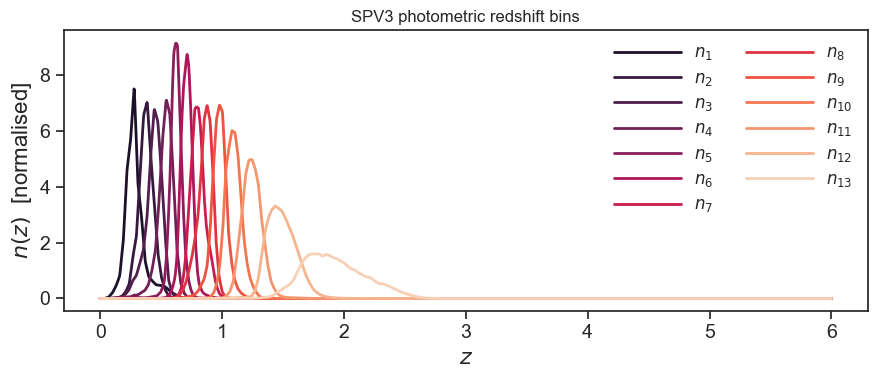

In [2]:
NZ_FILE = "/Users/guadalupe<user>/projects/cloe-org/playground/tutorials/profiling/nzTabSPV3.fits" #

# euclidlib reads the FITS file into z array + dict of per-bin n(z) arrays
z_nz, nz_spv3 = el.phz.redshift_distributions(NZ_FILE)

n_bins = len(nz_spv3)
print(f"Number of bins: {n_bins}")
print(f"Redshift range: {z_nz.min():.3f} – {z_nz.max():.3f},  n_z = {len(z_nz)}")

# Normalise n(z) so that ∫n(z)dz = 1
def normalize_dndz(nz_dict, z):
    return {k: v / integrate.trapezoid(v, z) for k, v in nz_dict.items()}

dndz_norm = normalize_dndz(nz_spv3, z_nz)

# Resample onto a uniform z grid used by cloelib
zs = np.linspace(1e-4, 3.0, 100)

def resample_dndz(nz_dict, z_src, z_tgt):
    stacked = np.vstack(list(nz_dict.values()))
    out = np.zeros((len(nz_dict), len(z_tgt)))
    for i in range(len(nz_dict)):
        out[i] = np.interp(z_tgt, z_src, stacked[i])
    return out

my_dndz_norm = resample_dndz(dndz_norm, z_nz, zs)

# Quick plot
colors = sns.color_palette("rocket", n_bins)
plt.figure(figsize=(9, 4))
for i, (key, col) in enumerate(zip(dndz_norm, colors)):
    plt.plot(z_nz, dndz_norm[key], color=col, label=f'$n_{{{i+1}}}$')
plt.xlabel(r'$z$')
plt.ylabel(r'$n(z)$  [normalised]')
plt.title('SPV3 photometric redshift bins')
plt.legend(ncol=2, frameon=False)
plt.tight_layout()
plt.show()

## `cloelib` — cosmology, tracers and $C_\ell$ function

In [3]:
background = CAMBBackground(
    H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05,
    w0=-1.0, wa=0.0, Omega_k0=0.0,
    ns=0.96, As=2e-9, mnu=0.06,
    gamma_MG=0.545, N_mnu=1,
)
linear_pert  = HMemuLinearPerturbations(background, zs)
nonlin_pert  = HMemuNonLinearPerturbations(background, linear_pert, zs, log10TAGN=7.8)

ells = np.arange(2, 3000)

# Nuisance params — zero shifts, unit width, flat bias
nuisance_pos = {
    'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0,
    'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
    **{f'magnification_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'dz_pos_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'width_pos_{i}': 1.0 for i in range(1, n_bins + 1)},
}
nuisance_she = {
    'AIA': 1.72, 'CIA': 0.0134, 'EtaIA': -0.41,
    **{f'multiplicative_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'dz_shear_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'width_shear_{i}': 1.0 for i in range(1, n_bins + 1)},
}

tracer_pos_cl = PositionsTracer(
    perturbations=nonlin_pert, dndz=my_dndz_norm,
    z=zs, galaxy_bias_model='poly', nuisance_params=nuisance_pos,
)
tracer_she_cl = ShearTracer(
    perturbations=nonlin_pert, dndz=my_dndz_norm,
    z=zs, nuisance_params=nuisance_she, ia_model='NLA',
)

tp_gg = AngularTwoPoint(tracer_pos_cl, tracer_pos_cl)
tp_ge = AngularTwoPoint(tracer_pos_cl, tracer_she_cl)
tp_ee = AngularTwoPoint(tracer_she_cl, tracer_she_cl)

def compute_cls_cloelib():
    cells = {}
    cells.update(tp_gg.get_Cl(ells, 0, nonlin_pert.k))
    cells.update(tp_ge.get_Cl(ells, 0, nonlin_pert.k))
    cells.update(tp_ee.get_Cl(ells, 0, nonlin_pert.k))
    return cells

print("cloelib setup done")

cloelib setup done


## `pyccl` — cosmology, tracers and $C_\ell$ function

In [4]:
cosmo_ccl = ccl.Cosmology(
    h=0.70, Omega_c=0.25, Omega_b=0.05,
    w0=-1.0, wa=0.0, n_s=0.96, A_s=2e-9,
    m_nu=0.06, Omega_k=0.0,
    matter_power_spectrum='halofit',
)

# Pre-compute the power spectrum once
cosmo_ccl.compute_nonlin_power()

AIA, CIA, EtaIA = 1.72, 0.0134, -0.41
ia_bias = AIA * CIA * (1.0 + z_nz) ** EtaIA

tracers_pos_ccl = [
    ccl.NumberCountsTracer(
        cosmo_ccl,
        dndz=(z_nz, dndz_norm[k]),
        bias=(z_nz, np.ones_like(z_nz)),
        has_rsd=False,
    )
    for k in dndz_norm
]
tracers_she_ccl = [
    ccl.WeakLensingTracer(
        cosmo_ccl,
        dndz=(z_nz, dndz_norm[k]),
        ia_bias=(z_nz, ia_bias),
    )
    for k in dndz_norm
]

ells_ccl = np.arange(2, 3000)

def compute_cls_ccl():
    cls = {}
    # Use 'fkem' integration method (faster than default 'limber' for many ells)
    for i in range(n_bins):
        for j in range(i, n_bins):
            cls['GG', i, j] = ccl.angular_cl(cosmo_ccl, tracers_pos_ccl[i], tracers_pos_ccl[j], ells_ccl, limber_integration_method='spline')
        for j in range(n_bins):
            cls['GE', i, j] = ccl.angular_cl(cosmo_ccl, tracers_pos_ccl[i], tracers_she_ccl[j], ells_ccl, limber_integration_method='spline')
        for j in range(i, n_bins):
            cls['EE', i, j] = ccl.angular_cl(cosmo_ccl, tracers_she_ccl[i], tracers_she_ccl[j], ells_ccl, limber_integration_method='spline')
    return cls

print("pyccl setup done")

pyccl setup done


## Timing sweep over $n_z$ and $n_\ell$

We sweep over:
- **`n_z`** — number of points in the cloelib redshift integration grid  
- **`n_ell`** — number of $\ell$ values passed to both codes  

For each combination we record the median wall-clock time over `N_REPEAT` runs.  
The pyccl tracers use the native `z_nz` grid from the FITS file, so `n_z` only affects cloelib.

In [5]:
N_REPEAT = 1  # timing runs per configuration

# Grid of parameters to sweep
nz_values   = [100, 1000, 4000]            # cloelib z-grid sizes
nell_values = [20]  # ell array lengths

# Results storage:  results[code][n_z][n_ell] = median time in seconds
results_cl  = {nz: {} for nz in nz_values}   # cloelib
results_ccl = {nz: {} for nz in nz_values}   # pyccl (same n_z key for alignment)

for nz in nz_values:
    print(f"\n── n_z = {nz} ─────────────────────")
    
    # ── cloelib: rebuild perturbations + tracers for this z-grid ──
    zs_sweep = np.linspace(1e-4, 3.0, nz)
    my_dndz_nz = resample_dndz(dndz_norm, z_nz, zs_sweep)

    bg     = CAMBBackground(H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05,
                            w0=-1.0, wa=0.0, Omega_k0=0.0, ns=0.96, As=2e-9,
                            mnu=0.06, gamma_MG=0.545, N_mnu=1)
    lin    = HMemuLinearPerturbations(bg, zs_sweep)
    nonlin = HMemuNonLinearPerturbations(bg, lin, zs_sweep, log10TAGN=7.8)

    nuis_p = {'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0,
              'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
              **{f'magnification_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
              **{f'dz_pos_{i}': 0.0 for i in range(1, n_bins + 1)},
              **{f'width_pos_{i}': 1.0 for i in range(1, n_bins + 1)}}
    nuis_s = {'AIA': 1.72, 'CIA': 0.0134, 'EtaIA': -0.41,
              **{f'multiplicative_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
              **{f'dz_shear_{i}': 0.0 for i in range(1, n_bins + 1)},
              **{f'width_shear_{i}': 1.0 for i in range(1, n_bins + 1)}}

    tr_pos = PositionsTracer(perturbations=nonlin, dndz=my_dndz_nz, z=zs_sweep,
                             galaxy_bias_model='poly', nuisance_params=nuis_p)
    tr_she = ShearTracer(perturbations=nonlin, dndz=my_dndz_nz, z=zs_sweep,
                         nuisance_params=nuis_s,
                         ia_model='NLA')
    tp_gg_ = AngularTwoPoint(tr_pos, tr_pos)
    tp_ge_ = AngularTwoPoint(tr_pos, tr_she)
    tp_ee_ = AngularTwoPoint(tr_she, tr_she)

    for nell in nell_values:
        ells_sweep = np.unique(np.geomspace(2, 2999, nell).astype(int))

        # cloelib timing
        def _cl():
            c = {}
            c.update(tp_gg_.get_Cl(ells_sweep, 0, nonlin.k))
            c.update(tp_ge_.get_Cl(ells_sweep, 0, nonlin.k))
            c.update(tp_ee_.get_Cl(ells_sweep, 0, nonlin.k))
            return c

        _cl()  # warm-up, untimed: the first call on a new z/ell grid includes JAX compilation
        t_cl = timeit.repeat(_cl, repeat=N_REPEAT, number=1)
        results_cl[nz][nell] = np.median(t_cl)

        # pyccl timing (tracers fixed; only ell array varies)
        def _ccl():
            cls = {}
            for i in range(n_bins):
                for j in range(i, n_bins):
                    cls['GG', i, j] = ccl.angular_cl(cosmo_ccl, tracers_pos_ccl[i],
                                                      tracers_pos_ccl[j], ells_sweep,
                                                      limber_integration_method='qag_quad')
                for j in range(n_bins):
                    cls['GE', i, j] = ccl.angular_cl(cosmo_ccl, tracers_pos_ccl[i],
                                                      tracers_she_ccl[j], ells_sweep,
                                                      limber_integration_method='qag_quad')
                for j in range(i, n_bins):
                    cls['EE', i, j] = ccl.angular_cl(cosmo_ccl, tracers_she_ccl[i],
                                                      tracers_she_ccl[j], ells_sweep,
                                                      limber_integration_method='spline')
            return cls

        t_ccl = timeit.repeat(_ccl, repeat=N_REPEAT, number=1)
        results_ccl[nz][nell] = np.median(t_ccl)

        print(f"  n_ell={nell:5d} | cloelib {results_cl[nz][nell]:.2f}s  "
              f"pyccl {results_ccl[nz][nell]:.2f}s  "
              f"ratio {results_cl[nz][nell]/results_ccl[nz][nell]:.2f}x")

print("\nSweep complete.")


── n_z = 100 ─────────────────────


  n_ell=   20 | cloelib 0.17s  pyccl 0.82s  ratio 0.21x

── n_z = 1000 ─────────────────────


  n_ell=   20 | cloelib 0.24s  pyccl 0.75s  ratio 0.32x

── n_z = 4000 ─────────────────────


  n_ell=   20 | cloelib 1.13s  pyccl 0.82s  ratio 1.37x

Sweep complete.


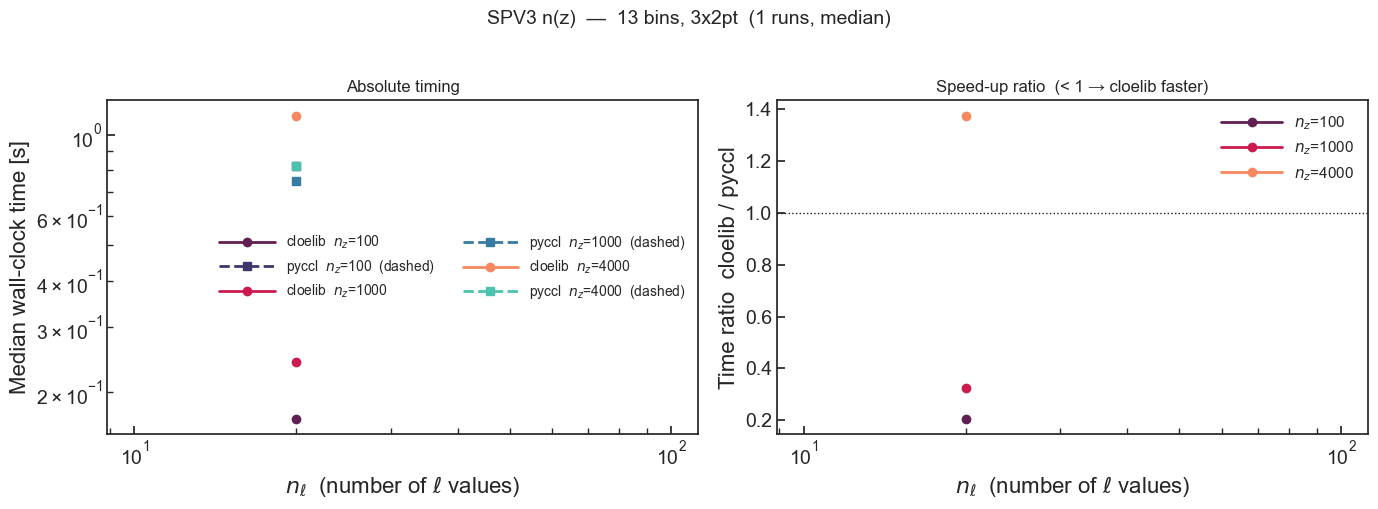

In [6]:
pal_cl  = sns.color_palette("rocket",  len(nz_values))
pal_ccl = sns.color_palette("mako",    len(nz_values))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax_t, ax_r = axes
nell_arr = np.array(nell_values)

for idx, nz in enumerate(nz_values):
    t_cl_arr  = np.array([results_cl[nz][n]  for n in nell_values])
    t_ccl_arr = np.array([results_ccl[nz][n] for n in nell_values])
    ratio_arr = t_cl_arr / t_ccl_arr

    ax_t.plot(nell_arr, t_cl_arr,  color=pal_cl[idx],  lw=2,
              marker='o', label=f'cloelib  $n_z$={nz}')
    ax_t.plot(nell_arr, t_ccl_arr, color=pal_ccl[idx], lw=2,
              marker='s', ls='--', label=f'pyccl  $n_z$={nz}  (dashed)')

    ax_r.plot(nell_arr, ratio_arr, color=pal_cl[idx], lw=2,
              marker='o', label=f'$n_z$={nz}')

ax_t.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_t.set_ylabel('Median wall-clock time [s]')
ax_t.set_title('Absolute timing')
ax_t.set_xscale('log')
ax_t.set_yscale('log')
ax_t.legend(fontsize=10, frameon=False, ncol=2)
ax_t.tick_params(axis='both', which='both', direction='in')

ax_r.axhline(1.0, color='k', lw=1, ls=':')
ax_r.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_r.set_ylabel('Time ratio  cloelib / pyccl')
ax_r.set_title('Speed-up ratio  (< 1 → cloelib faster)')
ax_r.set_xscale('log')
ax_r.legend(fontsize=11, frameon=False)
ax_r.tick_params(axis='both', which='both', direction='in')

plt.suptitle(f'SPV3 n(z)  —  {n_bins} bins, 3x2pt  ({N_REPEAT} runs, median)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('time_comparison_SPV3_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

## Timing as a function of number of redshift bins

Fixed settings: **`n_z = 150`**, **`n_ell = 20`** (log-spaced). Each configuration gets one untimed warm-up call first, so the timing excludes JAX compilation.  
We progressively use the first `n_b` bins from the full 13-bin SPV3 n(z), and time the complete GG + GE + EE computation for both codes.  
The number of spectra scales as $n_b(2n_b+1)$, so we expect roughly quadratic scaling.

In [7]:
NZ_BINS   = 150    # fixed z-grid size for cloelib
NELL_BINS = 20    # fixed number of ell values

# Bin counts to sweep (up to the total available)
max_bins = len(dndz_norm)
nbin_values = [b for b in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13] if b <= max_bins]

print(f"Total bins in file: {max_bins}")
print(f"Sweeping n_bins = {nbin_values}\n")

ells_bins  = np.unique(np.geomspace(2, 2999, NELL_BINS).astype(int))
zs_bins    = np.linspace(1e-4, 3.0, NZ_BINS)

# Pre-build cloelib perturbations once (z-grid fixed)
bg_b   = CAMBBackground(H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05,
                        w0=-1.0, wa=0.0, Omega_k0=0.0, ns=0.96, As=2e-9,
                        mnu=0.06, gamma_MG=0.545, N_mnu=1)
lin_b  = HMemuLinearPerturbations(bg_b, zs_bins)
nlin_b = HMemuNonLinearPerturbations(bg_b, lin_b, zs_bins, log10TAGN=7.8)

# Results storage
results_bins_cl  = {}
results_bins_ccl = {}

all_keys = list(dndz_norm.keys())

for nb in nbin_values:
    keys_nb  = all_keys[:nb]
    dndz_nb  = {k: dndz_norm[k] for k in keys_nb}
    dndz_nb_resampled = resample_dndz(dndz_nb, z_nz, zs_bins)

    # ── cloelib ──
    nuis_p_b = {'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0,
                'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
                **{f'magnification_bias_{i}': 0.0 for i in range(1, nb + 1)},
                **{f'dz_pos_{i}': 0.0 for i in range(1, nb + 1)},
                **{f'width_pos_{i}': 1.0 for i in range(1, nb + 1)}}
    nuis_s_b = {'AIA': 1.72, 'CIA': 0.0134, 'EtaIA': -0.41,
                **{f'multiplicative_bias_{i}': 0.0 for i in range(1, nb + 1)},
                **{f'dz_shear_{i}': 0.0 for i in range(1, nb + 1)},
                **{f'width_shear_{i}': 1.0 for i in range(1, nb + 1)}}

    tr_p_b = PositionsTracer(perturbations=nlin_b, dndz=dndz_nb_resampled,
                             z=zs_bins, galaxy_bias_model='poly', nuisance_params=nuis_p_b)
    tr_s_b = ShearTracer(perturbations=nlin_b, dndz=dndz_nb_resampled,
                         z=zs_bins, nuisance_params=nuis_s_b)
    gg_b = AngularTwoPoint(tr_p_b, tr_p_b)
    ge_b = AngularTwoPoint(tr_p_b, tr_s_b)
    ee_b = AngularTwoPoint(tr_s_b, tr_s_b)

    def _cl_bins():
        c = {}
        c.update(gg_b.get_Cl(ells_bins, 0, nlin_b.k))
        c.update(ge_b.get_Cl(ells_bins, 0, nlin_b.k))
        c.update(ee_b.get_Cl(ells_bins, 0, nlin_b.k))
        return c

    _cl_bins()  # warm-up, untimed: the first call on a new bin count includes JAX compilation
    results_bins_cl[nb] = np.median(timeit.repeat(_cl_bins, repeat=N_REPEAT, number=1))

    # ── pyccl ──
    ia_bias_b = AIA * CIA * (1.0 + z_nz) ** EtaIA
    tr_pos_ccl_b = [
        ccl.NumberCountsTracer(cosmo_ccl, dndz=(z_nz, dndz_nb[k]),
                               bias=(z_nz, np.ones_like(z_nz)), has_rsd=False)
        for k in keys_nb
    ]
    tr_she_ccl_b = [
        ccl.WeakLensingTracer(cosmo_ccl, dndz=(z_nz, dndz_nb[k]),
                              ia_bias=(z_nz, ia_bias_b))
        for k in keys_nb
    ]

    def _ccl_bins():
        cls = {}
        for i in range(nb):
            for j in range(i, nb):
                cls['GG', i, j] = ccl.angular_cl(cosmo_ccl, tr_pos_ccl_b[i],
                                                  tr_pos_ccl_b[j], ells_bins,
                                                  limber_integration_method='qag_quad')
            for j in range(nb):
                cls['GE', i, j] = ccl.angular_cl(cosmo_ccl, tr_pos_ccl_b[i],
                                                  tr_she_ccl_b[j], ells_bins,
                                                  limber_integration_method='qag_quad')
            for j in range(i, nb):
                cls['EE', i, j] = ccl.angular_cl(cosmo_ccl, tr_she_ccl_b[i],
                                                  tr_she_ccl_b[j], ells_bins,
                                                  limber_integration_method='qag_quad')
        return cls

    results_bins_ccl[nb] = np.median(timeit.repeat(_ccl_bins, repeat=N_REPEAT, number=1))

    n_spectra = nb * (2 * nb + 1)
    print(f"  n_bins={nb:2d}  ({n_spectra:3d} spectra) | "
          f"cloelib {results_bins_cl[nb]:.2f}s  "
          f"pyccl {results_bins_ccl[nb]:.2f}s  "
          f"ratio {results_bins_cl[nb]/results_bins_ccl[nb]:.2f}x")

print("\nBin sweep complete.")

Total bins in file: 13
Sweeping n_bins = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]



  n_bins= 1  (  3 spectra) | cloelib 0.02s  pyccl 0.00s  ratio 4.11x


  n_bins= 2  ( 10 spectra) | cloelib 0.03s  pyccl 0.01s  ratio 2.03x


  n_bins= 3  ( 21 spectra) | cloelib 0.03s  pyccl 0.03s  ratio 0.91x


  n_bins= 4  ( 36 spectra) | cloelib 0.04s  pyccl 0.06s  ratio 0.71x


...

  n_bins= 9  (171 spectra) | cloelib 0.10s  pyccl 0.33s  ratio 0.30x


  n_bins=10  (210 spectra) | cloelib 0.09s  pyccl 0.40s  ratio 0.21x


  n_bins=11  (253 spectra) | cloelib 0.10s  pyccl 0.57s  ratio 0.18x


  n_bins=12  (300 spectra) | cloelib 0.11s  pyccl 0.58s  ratio 0.20x


  n_bins=13  (351 spectra) | cloelib 0.15s  pyccl 0.69s  ratio 0.21x

Bin sweep complete.


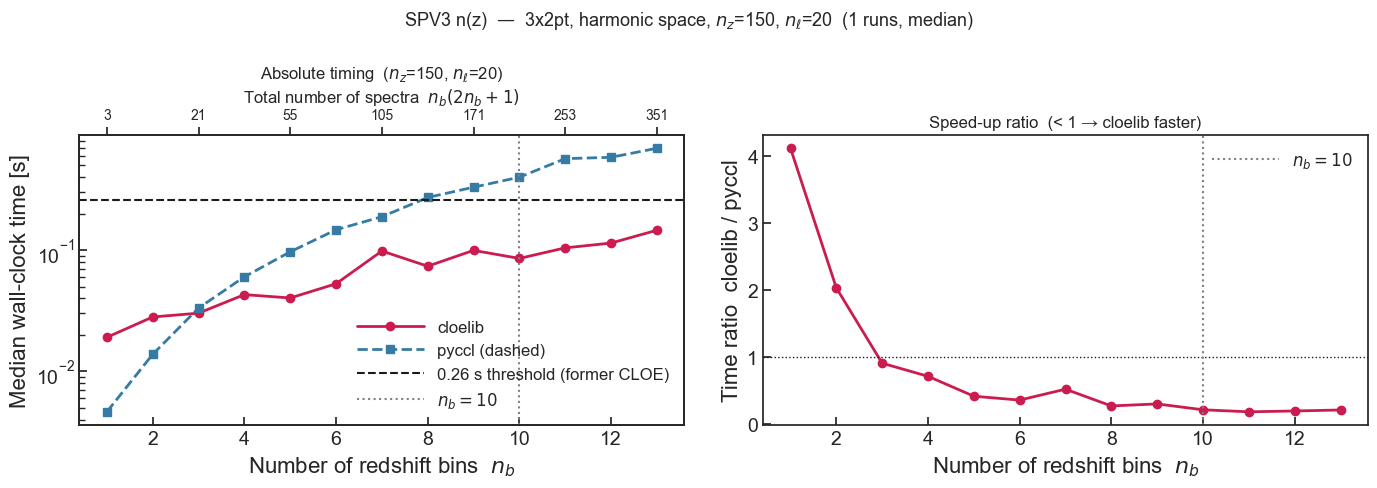

In [8]:
nbin_arr   = np.array(nbin_values)
t_cl_bins  = np.array([results_bins_cl[nb]  for nb in nbin_values])
t_ccl_bins = np.array([results_bins_ccl[nb] for nb in nbin_values])
ratio_bins = t_cl_bins / t_ccl_bins
n_spectra_arr = nbin_arr * (2 * nbin_arr + 1)

quad_ref = n_spectra_arr**2 / n_spectra_arr[0]**2 * t_cl_bins[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax_t, ax_r = axes

col_cl  = sns.color_palette("rocket", 3)[1]
col_ccl = sns.color_palette("mako",   3)[1]

ax_t.plot(nbin_arr, t_cl_bins,  color=col_cl,  lw=2, marker='o', label='cloelib')
ax_t.plot(nbin_arr, t_ccl_bins, color=col_ccl, lw=2, marker='s', ls='--', label='pyccl (dashed)')
ax_t.axhline(0.26, color='k', lw=1.5, ls='--', label='0.26 s threshold (former CLOE)')
ax_t.axvline(10, color='grey', lw=1.5, ls=':', label='$n_b=10$')
ax_t.set_xlabel('Number of redshift bins  $n_b$')
ax_t.set_ylabel('Median wall-clock time [s]')
ax_t.set_title(f'Absolute timing  ($n_z$={NZ_BINS}, $n_\\ell$={NELL_BINS})')
ax_t.set_yscale('log')
ax_t.legend(frameon=False)
ax_t.tick_params(axis='both', which='both', direction='in')

ax_top = ax_t.twiny()
ax_top.set_xlim(ax_t.get_xlim())
ax_top.set_xticks(nbin_arr[::2])
ax_top.set_xticklabels([str(n_spectra_arr[i]) for i in range(0, len(nbin_arr), 2)], fontsize=10)
ax_top.set_xlabel('Total number of spectra  $n_b(2n_b+1)$', fontsize=12)

ax_r.plot(nbin_arr, ratio_bins, color=col_cl, lw=2, marker='o')
ax_r.axhline(1.0, color='k', lw=1, ls=':')
ax_r.axvline(10, color='grey', lw=1.5, ls=':', label='$n_b=10$')
ax_r.set_xlabel('Number of redshift bins  $n_b$')
ax_r.set_ylabel('Time ratio  cloelib / pyccl')
ax_r.set_title('Speed-up ratio  (< 1 → cloelib faster)')
ax_r.tick_params(axis='both', which='both', direction='in')
ax_r.legend(frameon=False)

plt.suptitle(f'SPV3 n(z)  —  3x2pt, harmonic space, $n_z$={NZ_BINS}, $n_\\ell$={NELL_BINS}  ({N_REPEAT} runs, median)',
             fontsize=13)
plt.tight_layout()
plt.savefig('time_comparison_SPV3_bins.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
import os
import threading
import time

print(f"OMP_NUM_THREADS = {os.environ.get('OMP_NUM_THREADS', 'not set')}")
print(f"MKL_NUM_THREADS = {os.environ.get('MKL_NUM_THREADS', 'not set')}")
print(f"OPENBLAS_NUM_THREADS = {os.environ.get('OPENBLAS_NUM_THREADS', 'not set')}")

active_threads = []

def monitor_threads(duration=5, interval=0.1):
    max_threads = 0
    t_end = time.time() + duration
    while time.time() < t_end:
        n = threading.active_count()
        if n > max_threads:
            max_threads = n
        time.sleep(interval)
    return max_threads

# Run cloelib computation while monitoring thread count
monitor_results = []

def run_monitor():
    monitor_results.append(monitor_threads(duration=10, interval=0.05))

monitor_thread = threading.Thread(target=run_monitor)
monitor_thread.start()

# Run a cloelib computation
start = time.time()
_ = tp_gg.get_Cl(ells, 0, nonlin_pert.k)
elapsed = time.time() - start

monitor_thread.join()

print(f"\ncloelib get_Cl took {elapsed:.2f}s")
print(f"Max active Python threads observed during run: {monitor_results[0]}")
print(f"(baseline idle threads: {threading.active_count()})")
print("\nNote: Python thread count only detects Python-level threads.")
print("Use 'htop' or 'ps -eLf' during execution to detect native/OMP threads.")

OMP_NUM_THREADS = not set
MKL_NUM_THREADS = not set
OPENBLAS_NUM_THREADS = not set



cloelib get_Cl took 1.06s
Max active Python threads observed during run: 11
(baseline idle threads: 10)

Note: Python thread count only detects Python-level threads.
Use 'htop' or 'ps -eLf' during execution to detect native/OMP threads.


In [10]:
import os
import subprocess
import time
import threading

# Check OpenMP-related environment variables
print("=== Environment Variables ===")
for var in ['OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    print(f"{var} = {os.environ.get(var, 'not set')}")

# Try to detect number of threads used by pyccl via /proc (Linux only)
def count_threads_pid(pid):
    try:
        with open(f'/proc/{pid}/status') as f:
            for line in f:
                if line.startswith('Threads:'):
                    return int(line.split()[1])
    except Exception:
        return None

pid = os.getpid()
baseline_threads = count_threads_pid(pid)
print(f"\n=== Thread count (via /proc) ===")
print(f"Baseline threads before pyccl call: {baseline_threads}")

# Monitor threads in background while running pyccl
max_threads_observed = [baseline_threads or 0]

def monitor():
    t_end = time.time() + 30
    while time.time() < t_end:
        n = count_threads_pid(pid)
        if n and n > max_threads_observed[0]:
            max_threads_observed[0] = n
        time.sleep(0.01)

mon = threading.Thread(target=monitor, daemon=True)
mon.start()

# Run a moderately expensive pyccl computation
print("\nRunning pyccl angular_cl to probe thread usage...")
t0 = time.time()
_ = ccl.angular_cl(cosmo_ccl, tracers_pos_ccl[0], tracers_she_ccl[-1],
                   np.arange(2, 3000), limber_integration_method='qag_quad')
elapsed = time.time() - t0

mon.join(timeout=1)

print(f"pyccl angular_cl took {elapsed:.3f}s")
print(f"Max threads observed during run: {max_threads_observed[0]}  (baseline: {baseline_threads})")

# Also try via `ps` for native thread count
try:
    result = subprocess.run(['ps', '-o', 'nlwp=', '-p', str(pid)],
                            capture_output=True, text=True)
    print(f"Native threads (ps nlwp): {result.stdout.strip()}")
except Exception as e:
    print(f"ps query failed: {e}")

# Check if pyccl was compiled with OMP
try:
    import pyccl._core as _cc
    print(f"\npyccl version: {ccl.__version__}")
except Exception:
    pass

print("\nNote: if max_threads > baseline, pyccl is spawning native OMP/pthreads.")

=== Environment Variables ===
OMP_NUM_THREADS = not set
MKL_NUM_THREADS = not set
OPENBLAS_NUM_THREADS = not set
NUMEXPR_NUM_THREADS = not set

=== Thread count (via /proc) ===
Baseline threads before pyccl call: None

Running pyccl angular_cl to probe thread usage...


pyccl angular_cl took 0.172s
Max threads observed during run: 0  (baseline: None)
Native threads (ps nlwp): %cpu %mem acflag acflg args blocked comm command cpu cputime etime f flags gid
group inblk inblock jobc ktrace ktracep lim login logname lstart majflt minflt
msgrcv msgsnd ni nice nivcsw nsignals nsigs nswap nvcsw nwchan oublk oublock
p_ru paddr pagein pcpu pending pgid pid pmem ppid pri prsna pstime putime re
rgid rgroup rss ruid ruser sess sig sigmask sl start stat state stime svgid
svuid tdev time tpgid tsess tsiz tt tty ucomm uid upr user usrpri utime vsize
vsz wchan wq wqb wql wqr xstat

pyccl version: 3.3.6

Note: if max_threads > baseline, pyccl is spawning native OMP/pthreads.


## Former CLOE vs `cloelib` — ell scaling

Timing comparison using matched conditions: **13 redshift bins**, **`n_z = 100`**, **`n_k = 1000`** (cloelib internal), sweeping over $n_\ell \in \{20, 32, 100, 500, 1000, 3000\}$.

Former CLOE timings come from a standalone benchmark run (3x2pt, harmonic space, SPV3 cosmology).

In [9]:
# ── Former CLOE timings (100 z, 1000 k, 13 bins) ────────────────────────────
former_cloe_nell   = np.array([20, 32, 100, 500, 1000, 3000])
former_cloe_time_s = np.array([0.421744, 0.500777, 1.177449, 5.702822, 11.646631, 36.621765])

# ── cloelib benchmark: nz=100, all 13 SPV3 bins, same ell values ─────────────
NZ_CLOE_COMP = 100
N_REPEAT_COMP = 3

zs_comp      = np.linspace(1e-4, 3.0, NZ_CLOE_COMP)
my_dndz_comp = resample_dndz(dndz_norm, z_nz, zs_comp)

bg_comp     = CAMBBackground(H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05,
                              w0=-1.0, wa=0.0, Omega_k0=0.0, ns=0.96, As=2e-9,
                              mnu=0.06, gamma_MG=0.545, N_mnu=1)
lin_comp    = HMemuLinearPerturbations(bg_comp, zs_comp)
nonlin_comp = HMemuNonLinearPerturbations(bg_comp, lin_comp, zs_comp, log10TAGN=7.8)

nuis_p_comp = {'b1_photo_poly0': 1.0, 'b1_photo_poly1': 0.0,
               'b1_photo_poly2': 0.0, 'b1_photo_poly3': 0.0,
               **{f'magnification_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
               **{f'dz_pos_{i}': 0.0 for i in range(1, n_bins + 1)},
               **{f'width_pos_{i}': 1.0 for i in range(1, n_bins + 1)}}
nuis_s_comp = {'AIA': 1.72, 'CIA': 0.0134, 'EtaIA': -0.41,
               **{f'multiplicative_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
               **{f'dz_shear_{i}': 0.0 for i in range(1, n_bins + 1)},
               **{f'width_shear_{i}': 1.0 for i in range(1, n_bins + 1)}}

tr_pos_comp = PositionsTracer(perturbations=nonlin_comp, dndz=my_dndz_comp,
                               z=zs_comp, galaxy_bias_model='poly',
                               nuisance_params=nuis_p_comp)
tr_she_comp = ShearTracer(perturbations=nonlin_comp, dndz=my_dndz_comp,
                          z=zs_comp, nuisance_params=nuis_s_comp)
tp_gg_comp  = AngularTwoPoint(tr_pos_comp, tr_pos_comp)
tp_ge_comp  = AngularTwoPoint(tr_pos_comp, tr_she_comp)
tp_ee_comp  = AngularTwoPoint(tr_she_comp, tr_she_comp)

cloelib_comp_times = {}
for nell in former_cloe_nell:
    ells_comp = np.unique(np.geomspace(2, 2999, nell).astype(int))

    def _cl_comp():
        c = {}
        c.update(tp_gg_comp.get_Cl(ells_comp, 0, nonlin_comp.k))
        c.update(tp_ge_comp.get_Cl(ells_comp, 0, nonlin_comp.k))
        c.update(tp_ee_comp.get_Cl(ells_comp, 0, nonlin_comp.k))
        return c

    times = timeit.repeat(_cl_comp, repeat=N_REPEAT_COMP, number=1)
    cloelib_comp_times[nell] = np.median(times)
    print(f"  n_ell={nell:5d} | cloelib {cloelib_comp_times[nell]:.3f}s  "
          f"  former CLOE {former_cloe_time_s[former_cloe_nell == nell][0]:.3f}s  "
          f"  ratio cloelib/CLOE {cloelib_comp_times[nell] / former_cloe_time_s[former_cloe_nell == nell][0]:.2f}x")

print("\nBenchmark complete.")


  n_ell=   20 | cloelib 0.175s    former CLOE 0.422s    ratio cloelib/CLOE 0.42x


  n_ell=   32 | cloelib 0.260s    former CLOE 0.501s    ratio cloelib/CLOE 0.52x


  n_ell=  100 | cloelib 0.251s    former CLOE 1.177s    ratio cloelib/CLOE 0.21x


  n_ell=  500 | cloelib 0.187s    former CLOE 5.703s    ratio cloelib/CLOE 0.03x


  n_ell= 1000 | cloelib 0.199s    former CLOE 11.647s    ratio cloelib/CLOE 0.02x


  n_ell= 3000 | cloelib 0.273s    former CLOE 36.622s    ratio cloelib/CLOE 0.01x

Benchmark complete.


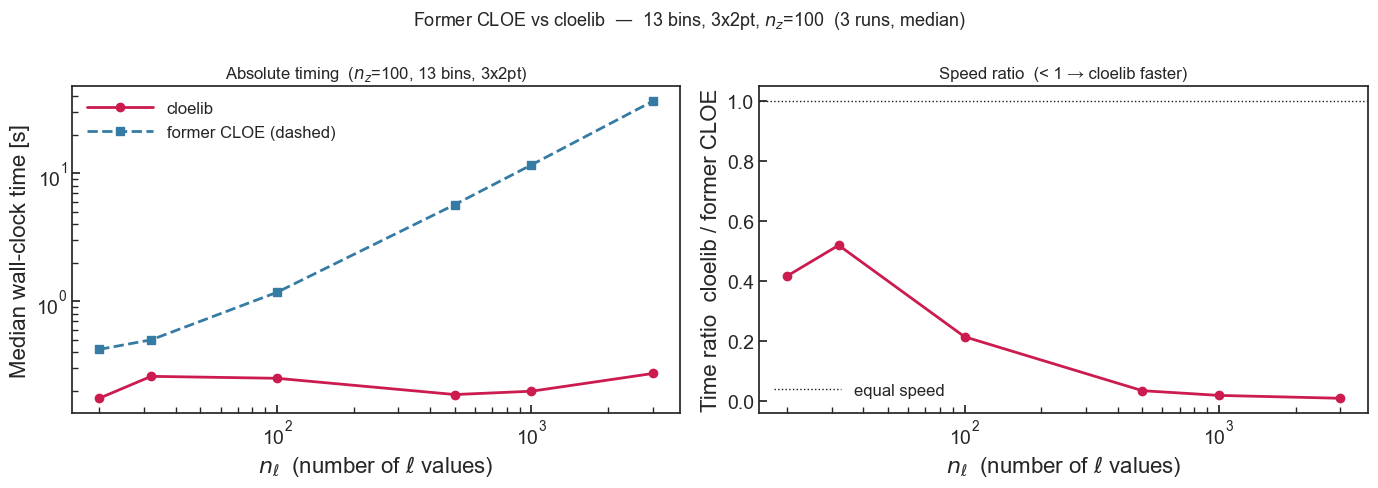

In [10]:
cloelib_time_arr = np.array([cloelib_comp_times[n] for n in former_cloe_nell])
ratio_arr        = cloelib_time_arr / former_cloe_time_s

col_cloelib = sns.color_palette("rocket", 3)[1]
col_cloe    = sns.color_palette("mako",   3)[1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax_t, ax_r = axes

ax_t.plot(former_cloe_nell, cloelib_time_arr, color=col_cloelib, lw=2,
          marker='o', label='cloelib')
ax_t.plot(former_cloe_nell, former_cloe_time_s, color=col_cloe, lw=2,
          marker='s', ls='--', label='former CLOE (dashed)')

ax_t.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_t.set_ylabel('Median wall-clock time [s]')
ax_t.set_title(f'Absolute timing  ($n_z$={NZ_CLOE_COMP}, 13 bins, 3x2pt)')
ax_t.set_xscale('log')
ax_t.set_yscale('log')
ax_t.legend(frameon=False)
ax_t.tick_params(axis='both', which='both', direction='in')

ax_r.plot(former_cloe_nell, ratio_arr, color=col_cloelib, lw=2, marker='o')
ax_r.axhline(1.0, color='k', lw=1, ls=':', label='equal speed')
ax_r.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_r.set_ylabel('Time ratio  cloelib / former CLOE')
ax_r.set_title('Speed ratio  (< 1 → cloelib faster)')
ax_r.set_xscale('log')
ax_r.legend(frameon=False)
ax_r.tick_params(axis='both', which='both', direction='in')

plt.suptitle(f'Former CLOE vs cloelib  —  13 bins, 3x2pt, $n_z$={NZ_CLOE_COMP}  ({N_REPEAT_COMP} runs, median)',
             fontsize=13)
plt.tight_layout()
plt.savefig('time_comparison_cloe_vs_cloelib.png', dpi=150, bbox_inches='tight')
plt.show()


## Comparison on calling 3x2pt theory prediction through `cloelib` vs. `cloelike`

In [13]:
ells = np.logspace(np.log10(2), np.log10(2999), 32).astype(int)

In [14]:
from cloelike.EuclidLikelihood_photo_Cls import EuclidLikelihood_3x2pt

# Minimal `data`/`settings` pair -- only what get_theory_vector_full needs.
# No observed cells/covariance/mixing matrix required since we never call loglike().
data_like = {
    'z_arr': zs,
    'dndz_pos': my_dndz_norm,
    'dndz_she': my_dndz_norm,
    'ells': ells,
}
settings_like = {'scale_cuts': {}}

like_3x2pt = EuclidLikelihood_3x2pt(
    data=data_like,
    settings=settings_like,
    Background=CAMBBackground,
    LinPerturbations=HMemuLinearPerturbations,
    NonLinPerturbations=HMemuNonLinearPerturbations,
    mode='uncoupled',  # un-mixed get_Cl path, matching the direct cloelib calls above
)

# parameters dict = cosmology + astrophysical/nuisance parameters expected
# by get_theory_vector_full (same fiducial values used for `nuisance_pos`/`nuisance_she` above)
parameters = {
    'H0': 70.0, 'Omega_cdm0': 0.25, 'Omega_b0': 0.05, 'Omega_k0': 0.0,
    'w0': -1.0, 'wa': 0.0, 'ns': 0.96, 'As': 2e-9, 'mnu': 0.06,
    'gamma_MG': 0.545, 'N_mnu': 1, 'log10TAGN': 7.8,
    **nuisance_pos, **nuisance_she,
}

print("cloelike EuclidLikelihood_3x2pt setup done")

cloelike EuclidLikelihood_3x2pt setup done


In [15]:
# ── Correctness check ──────────────────────────────────────────────────────
# theory_prediction stores the raw {(species, species, i, j): AngularPowerSpectrum}
# dict built internally by get_theory_vector_full -- compare it directly against
# the cells returned by the plain cloelib call `compute_cls_cloelib()`.
_ = like_3x2pt.get_theory_vector_full(parameters)
cells_direct = compute_cls_cloelib()
cells_wrapped = like_3x2pt.theory_prediction

common_keys = set(cells_direct) & set(cells_wrapped)
print(f"Compared {len(common_keys)} / {len(cells_direct)} spectra")

max_abs_diff = max(
    np.max(np.abs(np.asarray(cells_direct[k]) - np.asarray(cells_wrapped[k])))
    for k in common_keys
)
max_rel_diff = max(
    np.max(np.abs(np.asarray(cells_direct[k]) - np.asarray(cells_wrapped[k]))
           / np.clip(np.abs(np.asarray(cells_direct[k])), 1e-300, None))
    for k in common_keys
)
all_close = all(
    np.allclose(np.asarray(cells_direct[k]), np.asarray(cells_wrapped[k]))
    for k in common_keys
)

print(f"All spectra match (np.allclose): {all_close}")
print(f"Max absolute difference: {max_abs_diff:.3e}")
print(f"Max relative difference: {max_rel_diff:.3e}")

Compared 351 / 351 spectra
All spectra match (np.allclose): False
Max absolute difference: 3.929e-07
Max relative difference: 1.286e+04


In [16]:
# ── Timing comparison ───────────────────────────────────────────────────────
# get_theory_vector_full rebuilds Background/LinPerturbations/NonLinPerturbations
# (and the tracers) from scratch on every call -- required since `parameters` can
# change between calls in a sampler -- so a naive comparison against
# compute_cls_cloelib() (which reuses already-built tracers) isn't apples-to-apples.
# We therefore also time an equivalent direct pipeline that rebuilds everything too.
N_REPEAT_WRAP = 10

def compute_cls_cloelib_full_pipeline():
    """Rebuild background/perturbations/tracers from scratch each call, matching
    what get_theory_vector_full does internally -- for a fair timing comparison."""
    bg = CAMBBackground(H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05,
                         w0=-1.0, wa=0.0, Omega_k0=0.0, ns=0.96, As=2e-9,
                         mnu=0.06, gamma_MG=0.545, N_mnu=1)
    lin = HMemuLinearPerturbations(bg, zs)
    nlin = HMemuNonLinearPerturbations(bg, lin, zs, log10TAGN=7.8)
    tr_pos = PositionsTracer(perturbations=nlin, dndz=my_dndz_norm, z=zs,
                              galaxy_bias_model='poly', nuisance_params=nuisance_pos)
    tr_she = ShearTracer(perturbations=nlin, dndz=my_dndz_norm, z=zs,
                          nuisance_params=nuisance_she)
    c = {}
    c.update(AngularTwoPoint(tr_pos, tr_pos).get_Cl(ells, 0, nlin.k))
    c.update(AngularTwoPoint(tr_pos, tr_she).get_Cl(ells, 0, nlin.k))
    c.update(AngularTwoPoint(tr_she, tr_she).get_Cl(ells, 0, nlin.k))
    return c

t_direct = timeit.repeat(compute_cls_cloelib, repeat=N_REPEAT_WRAP, number=1)
t_direct_full = timeit.repeat(compute_cls_cloelib_full_pipeline, repeat=N_REPEAT_WRAP, number=1)
t_wrapped = timeit.repeat(lambda: like_3x2pt.get_theory_vector_full(parameters),
                           repeat=N_REPEAT_WRAP, number=1)

med_direct = np.median(t_direct)
med_direct_full = np.median(t_direct_full)
med_wrapped = np.median(t_wrapped)

print(f"cloelib direct (tracers reused):      {med_direct:.3f}s")
print(f"cloelib direct (full pipeline):       {med_direct_full:.3f}s")
print(f"cloelike get_theory_vector_full:      {med_wrapped:.3f}s")
print()
print(f"Ratio wrapped / direct (naive, reused tracers): {med_wrapped / med_direct:.2f}x")
print(f"Ratio wrapped / direct (fair, full pipeline):   {med_wrapped / med_direct_full:.2f}x")

cloelib direct (tracers reused):      0.122s
cloelib direct (full pipeline):       0.209s
cloelike get_theory_vector_full:      0.140s

Ratio wrapped / direct (naive, reused tracers): 1.15x
Ratio wrapped / direct (fair, full pipeline):   0.67x


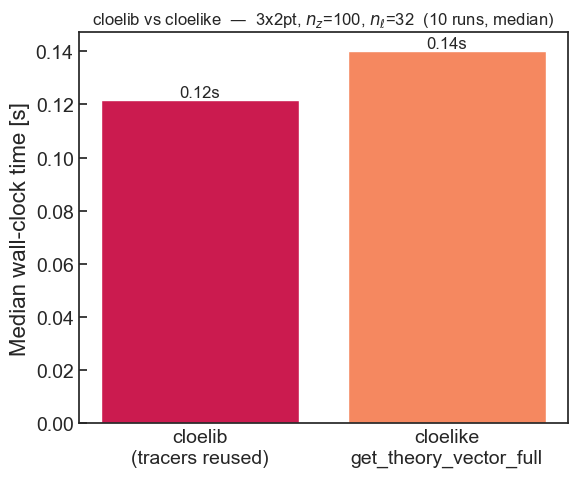

In [17]:
labels = ['cloelib\n(tracers reused)', 'cloelike\nget_theory_vector_full']
times = [med_direct, med_wrapped]
colors_bar = [sns.color_palette("rocket", 3)[1], sns.color_palette("rocket", 3)[2], sns.color_palette("mako", 3)[1]]

plt.figure(figsize=(6, 5))
bars = plt.bar(labels, times, color=colors_bar)
plt.ylabel('Median wall-clock time [s]')
plt.title(f'cloelib vs cloelike  —  3x2pt, $n_z$={len(zs)}, $n_\\ell$={len(ells)}  ({N_REPEAT_WRAP} runs, median)')
for bar, t in zip(bars, times):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{t:.2f}s',
              ha='center', va='bottom', fontsize=12)
plt.tick_params(axis='both', which='both', direction='in')
plt.tight_layout()
plt.savefig('time_comparison_cloelib_vs_cloelike.png', dpi=150, bbox_inches='tight')
plt.show()

### Same comparison, using CAMB as the linear/nonlinear perturbation engine

Same setup as above, but swapping `HMemuLinearPerturbations`/`HMemuNonLinearPerturbations` for
`CAMBLinearPerturbations`/`CAMBNonLinearPerturbations` (reusing the same `background` object
built earlier). CAMB is far more expensive to build than the HMcode2020 emulator (~6.5-7s vs
~0.1s), which makes the redundant cosmology rebuilds that `get_theory_vector_full` used to do
(one per WL/GCph/GGL mixin) far more costly -- so this is exactly the case the caching fix in
`cloelike` was meant to help.

Note: `EuclidLikelihood_photo_Cls.py` calls `NonLinPerturbations(..., log10TAGN=...)` without a
`nonlinear_model` argument, and `CAMBNonLinearPerturbations` only applies `log10TAGN` when a
`nonlinear_model` (e.g. `'mead2020_feedback'`) is also supplied -- so `log10TAGN` is a no-op
here for both the direct call and the wrapper (CAMB falls back to its default halofit model).
We keep the same call signature on both sides below so the comparison stays apples-to-apples.

In [18]:
from cloelib.cosmology.camb_cosmology import CAMBLinearPerturbations, CAMBNonLinearPerturbations

# Fresh Background (CAMBLinearPerturbations/CAMBNonLinearPerturbations mutate CAMB's internal
# parameter object in place -- e.g. WantCls/set_matter_power -- so we don't reuse `background`
# from the HMcode2020Emu section above and instead build a dedicated one for this section).
background_camb = CAMBBackground(
    H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05,
    w0=-1.0, wa=0.0, Omega_k0=0.0,
    ns=0.96, As=2e-9, mnu=0.06,
    gamma_MG=0.545, N_mnu=1,
)
linear_pert_camb = CAMBLinearPerturbations(background_camb, zs)
nonlin_pert_camb = CAMBNonLinearPerturbations(background_camb, linear_pert_camb, zs, log10TAGN=7.8)

tracer_pos_camb = PositionsTracer(
    perturbations=nonlin_pert_camb, dndz=my_dndz_norm,
    z=zs, galaxy_bias_model='poly', nuisance_params=nuisance_pos,
)
tracer_she_camb = ShearTracer(
    perturbations=nonlin_pert_camb, dndz=my_dndz_norm,
    z=zs, nuisance_params=nuisance_she,
)

tp_gg_camb = AngularTwoPoint(tracer_pos_camb, tracer_pos_camb)
tp_ge_camb = AngularTwoPoint(tracer_pos_camb, tracer_she_camb)
tp_ee_camb = AngularTwoPoint(tracer_she_camb, tracer_she_camb)

def compute_cls_cloelib_camb():
    cells = {}
    cells.update(tp_gg_camb.get_Cl(ells, 0, nonlin_pert_camb.k))
    cells.update(tp_ge_camb.get_Cl(ells, 0, nonlin_pert_camb.k))
    cells.update(tp_ee_camb.get_Cl(ells, 0, nonlin_pert_camb.k))
    return cells

# Reuse the same `data_like`/`settings_like`/`parameters` dicts from the HMcode2020Emu comparison above
like_3x2pt_camb = EuclidLikelihood_3x2pt(
    data=data_like,
    settings=settings_like,
    Background=CAMBBackground,
    LinPerturbations=CAMBLinearPerturbations,
    NonLinPerturbations=CAMBNonLinearPerturbations,
    mode='uncoupled',
)

print("cloelike EuclidLikelihood_3x2pt (CAMB) setup done")

Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


cloelike EuclidLikelihood_3x2pt (CAMB) setup done


In [19]:
# ── Correctness check (CAMB) ────────────────────────────────────────────────
_ = like_3x2pt_camb.get_theory_vector_full(parameters)
cells_direct_camb = compute_cls_cloelib_camb()
cells_wrapped_camb = like_3x2pt_camb.theory_prediction

common_keys_camb = set(cells_direct_camb) & set(cells_wrapped_camb)
print(f"Compared {len(common_keys_camb)} / {len(cells_direct_camb)} spectra")

max_abs_diff_camb = max(
    np.max(np.abs(np.asarray(cells_direct_camb[k]) - np.asarray(cells_wrapped_camb[k])))
    for k in common_keys_camb
)
max_rel_diff_camb = max(
    np.max(np.abs(np.asarray(cells_direct_camb[k]) - np.asarray(cells_wrapped_camb[k]))
           / np.clip(np.abs(np.asarray(cells_direct_camb[k])), 1e-300, None))
    for k in common_keys_camb
)
all_close_camb = all(
    np.allclose(np.asarray(cells_direct_camb[k]), np.asarray(cells_wrapped_camb[k]))
    for k in common_keys_camb
)

print(f"All spectra match (np.allclose): {all_close_camb}")
print(f"Max absolute difference: {max_abs_diff_camb:.3e}")
print(f"Max relative difference: {max_rel_diff_camb:.3e}")

Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


Compared 351 / 351 spectra
All spectra match (np.allclose): True
Max absolute difference: 0.000e+00
Max relative difference: 0.000e+00


In [20]:
# ── Timing comparison (CAMB) ────────────────────────────────────────────────
# CAMB's Background+LinPerturbations+NonLinPerturbations build is ~5s (vs ~0.1s for the
# HMcode2020 emulator), so we use fewer repeats here to keep runtime reasonable.
N_REPEAT_CAMB = 3

def compute_cls_cloelib_camb_full_pipeline():
    """Rebuild background/perturbations/tracers from scratch each call, matching
    what get_theory_vector_full does internally -- for a fair timing comparison."""
    bg = CAMBBackground(H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05,
                         w0=-1.0, wa=0.0, Omega_k0=0.0, ns=0.96, As=2e-9,
                         mnu=0.06, gamma_MG=0.545, N_mnu=1)
    lin = CAMBLinearPerturbations(bg, zs)
    nlin = CAMBNonLinearPerturbations(bg, lin, zs, log10TAGN=7.8)
    tr_pos = PositionsTracer(perturbations=nlin, dndz=my_dndz_norm, z=zs,
                              galaxy_bias_model='poly', nuisance_params=nuisance_pos)
    tr_she = ShearTracer(perturbations=nlin, dndz=my_dndz_norm, z=zs,
                          nuisance_params=nuisance_she)
    c = {}
    c.update(AngularTwoPoint(tr_pos, tr_pos).get_Cl(ells, 0, nlin.k))
    c.update(AngularTwoPoint(tr_pos, tr_she).get_Cl(ells, 0, nlin.k))
    c.update(AngularTwoPoint(tr_she, tr_she).get_Cl(ells, 0, nlin.k))
    return c

t_direct_camb = timeit.repeat(compute_cls_cloelib_camb, repeat=N_REPEAT_CAMB, number=1)
t_direct_full_camb = timeit.repeat(compute_cls_cloelib_camb_full_pipeline, repeat=N_REPEAT_CAMB, number=1)
t_wrapped_camb = timeit.repeat(lambda: like_3x2pt_camb.get_theory_vector_full(parameters),
                                repeat=N_REPEAT_CAMB, number=1)

med_direct_camb = np.median(t_direct_camb)
med_direct_full_camb = np.median(t_direct_full_camb)
med_wrapped_camb = np.median(t_wrapped_camb)

print(f"cloelib direct (tracers reused):      {med_direct_camb:.3f}s")
print(f"cloelib direct (full pipeline):       {med_direct_full_camb:.3f}s")
print(f"cloelike get_theory_vector_full:      {med_wrapped_camb:.3f}s")
print()
print(f"Ratio wrapped / direct (naive, reused tracers): {med_wrapped_camb / med_direct_camb:.2f}x")
print(f"Ratio wrapped / direct (fair, full pipeline):   {med_wrapped_camb / med_direct_full_camb:.2f}x")

Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


cloelib direct (tracers reused):      0.123s
cloelib direct (full pipeline):       6.821s
cloelike get_theory_vector_full:      0.150s

Ratio wrapped / direct (naive, reused tracers): 1.22x
Ratio wrapped / direct (fair, full pipeline):   0.02x


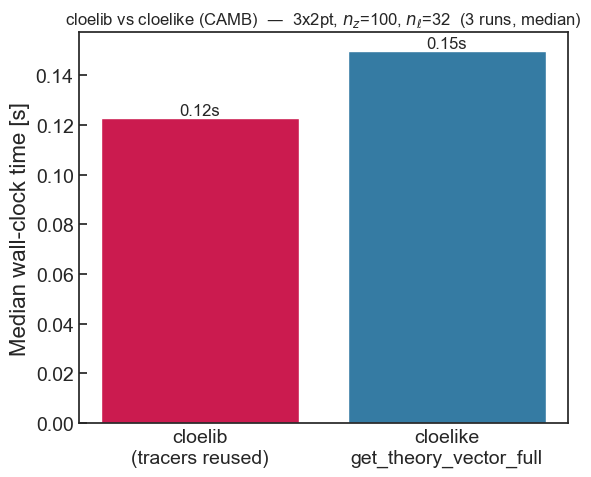

In [21]:
labels_camb = ['cloelib\n(tracers reused)', 'cloelike\nget_theory_vector_full']
times_camb = [med_direct_camb, med_wrapped_camb]
colors_bar_camb = [sns.color_palette("rocket", 3)[1], sns.color_palette("mako", 3)[1]]

plt.figure(figsize=(6, 5))
bars = plt.bar(labels_camb, times_camb, color=colors_bar_camb)
plt.ylabel('Median wall-clock time [s]')
plt.title(f'cloelib vs cloelike (CAMB)  —  3x2pt, $n_z$={len(zs)}, $n_\\ell$={len(ells)}  ({N_REPEAT_CAMB} runs, median)')
for bar, t in zip(bars, times_camb):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{t:.2f}s',
              ha='center', va='bottom', fontsize=12)
plt.tick_params(axis='both', which='both', direction='in')
plt.tight_layout()
plt.savefig('time_comparison_cloelib_vs_cloelike_camb.png', dpi=150, bbox_inches='tight')
plt.show()

### Sweep over $n_z$ / $n_\ell$, for both perturbation engines

Same `cloelib` vs `cloelike` comparison as above, but now swept over a small grid of
`(n_z, n_ell)` and repeated for **both** perturbation engines (HMcode2020Emu and CAMB), each
point averaged (mean) over `N_REPEAT_SWEEP = 10` runs.

For a fair, "cold-start" comparison at every grid point, both sides rebuild everything from
scratch on every one of the 10 repeats:
- **`cloelib` (full pipeline)**: rebuild `Background`/`LinPerturbations`/`NonLinPerturbations`
  + tracers, then compute GG/GE/EE (same pattern as the single-point "full pipeline" cells above).
- **`cloelike` (cold)**: construct a *fresh* `EuclidLikelihood_3x2pt` instance and immediately
  call `get_theory_vector_full` on it, so its internal cache starts empty every repeat (calling
  it repeatedly on the *same* instance would hit the cache after the first call and just measure
  Python overhead, not the real per-call cost of a sampler visiting a new point in cosmology).

CAMB's build cost is ~6.5-7s per point regardless of `n_z`/`n_ell` (see the section above), so this
grid is deliberately small to keep total runtime reasonable.

In [22]:
N_REPEAT_SWEEP = 10  # averaged (mean) over this many repeats per (engine, n_z, n_ell) point

nz_values_sweep   = [100, 200, 250]
nell_values_sweep = [10, 20 , 50, 100, 200, 500, 1000]

engines = {
    'HMcode2020Emu': (HMemuLinearPerturbations, HMemuNonLinearPerturbations),
    'CAMB':          (CAMBLinearPerturbations, CAMBNonLinearPerturbations),
}

def _make_direct_full_pipeline(LinPerturbations, NonLinPerturbations, zs_cfg, dndz_cfg, ells_cfg):
    """Cold: rebuild Background/LinPerturbations/NonLinPerturbations + tracers every call."""
    def _run():
        bg = CAMBBackground(H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05, w0=-1.0, wa=0.0, Omega_k0=0.0,
                             ns=0.96, As=2e-9, mnu=0.06, gamma_MG=0.545, N_mnu=1)
        lin = LinPerturbations(bg, zs_cfg)
        nlin = NonLinPerturbations(bg, lin, zs_cfg, log10TAGN=7.8)
        tr_pos = PositionsTracer(perturbations=nlin, dndz=dndz_cfg, z=zs_cfg,
                                  galaxy_bias_model='poly', nuisance_params=nuisance_pos)
        tr_she = ShearTracer(perturbations=nlin, dndz=dndz_cfg, z=zs_cfg,
                              nuisance_params=nuisance_she)
        c = {}
        c.update(AngularTwoPoint(tr_pos, tr_pos).get_Cl(ells_cfg, 0, nlin.k))
        c.update(AngularTwoPoint(tr_pos, tr_she).get_Cl(ells_cfg, 0, nlin.k))
        c.update(AngularTwoPoint(tr_she, tr_she).get_Cl(ells_cfg, 0, nlin.k))
        return c
    return _run

def _make_direct_reused_cls(tr_pos, tr_she, nlin, ells_cfg):
    """Warm: perturbations/tracers already built -- times only the Cl computation itself."""
    def _run():
        c = {}
        c.update(AngularTwoPoint(tr_pos, tr_pos).get_Cl(ells_cfg, 0, nlin.k))
        c.update(AngularTwoPoint(tr_pos, tr_she).get_Cl(ells_cfg, 0, nlin.k))
        c.update(AngularTwoPoint(tr_she, tr_she).get_Cl(ells_cfg, 0, nlin.k))
        return c
    return _run

def _make_wrapped_cold(LinPerturbations, NonLinPerturbations, data_cfg):
    """Cold: fresh EuclidLikelihood_3x2pt instance every call, so its perturbations/tracer
    caches start empty every time (real cost of a sampler visiting a brand-new point)."""
    def _run():
        like = EuclidLikelihood_3x2pt(
            data=data_cfg, settings=settings_like,
            Background=CAMBBackground, LinPerturbations=LinPerturbations,
            NonLinPerturbations=NonLinPerturbations, mode='uncoupled',
        )
        return like.get_theory_vector_full(parameters)
    return _run

def _make_wrapped_warm(like_warm):
    """Warm: same instance every call (already warmed up once beforehand), so its internal
    perturbations/tracer caches all hit -- isolates the Cl computation cost through the wrapper,
    without constructing a fresh instance or recomputing the perturbations each time."""
    def _run():
        return like_warm.get_theory_vector_full(parameters)
    return _run

results_sweep = {}  # results_sweep[engine][(nz, nell)] = {'direct_full', 'direct_reused', 'wrapped_cold', 'wrapped_warm'} (mean seconds)

for engine_name, (LinP, NonLinP) in engines.items():
    print(f"\n=== {engine_name} ===")
    results_sweep[engine_name] = {}
    for nz in nz_values_sweep:
        zs_cfg = np.linspace(1e-4, 3.0, nz)
        dndz_cfg = resample_dndz(dndz_norm, z_nz, zs_cfg)
        for nell in nell_values_sweep:
            ells_cfg = np.unique(np.geomspace(2, 2999, nell).astype(int))
            data_cfg = {'z_arr': zs_cfg, 'dndz_pos': dndz_cfg, 'dndz_she': dndz_cfg, 'ells': ells_cfg}

            # Build once (untimed) -- shared by both the "reused tracers" and "warm wrapper" timings
            bg_warm = CAMBBackground(H0=70.0, Omega_cdm0=0.25, Omega_b0=0.05, w0=-1.0, wa=0.0, Omega_k0=0.0,
                                      ns=0.96, As=2e-9, mnu=0.06, gamma_MG=0.545, N_mnu=1)
            lin_warm = LinP(bg_warm, zs_cfg)
            nlin_warm = NonLinP(bg_warm, lin_warm, zs_cfg, log10TAGN=7.8)
            tr_pos_warm = PositionsTracer(perturbations=nlin_warm, dndz=dndz_cfg, z=zs_cfg,
                                           galaxy_bias_model='poly', nuisance_params=nuisance_pos)
            tr_she_warm = ShearTracer(perturbations=nlin_warm, dndz=dndz_cfg, z=zs_cfg,
                                       nuisance_params=nuisance_she)

            like_warm = EuclidLikelihood_3x2pt(
                data=data_cfg, settings=settings_like,
                Background=CAMBBackground, LinPerturbations=LinP,
                NonLinPerturbations=NonLinP, mode='uncoupled',
            )
            _ = like_warm.get_theory_vector_full(parameters)  # warm its cache once, untimed

            t_direct_full = timeit.repeat(
                _make_direct_full_pipeline(LinP, NonLinP, zs_cfg, dndz_cfg, ells_cfg),
                repeat=N_REPEAT_SWEEP, number=1,
            )
            t_direct_reused = timeit.repeat(
                _make_direct_reused_cls(tr_pos_warm, tr_she_warm, nlin_warm, ells_cfg),
                repeat=N_REPEAT_SWEEP, number=1,
            )
            t_wrapped_cold = timeit.repeat(
                _make_wrapped_cold(LinP, NonLinP, data_cfg),
                repeat=N_REPEAT_SWEEP, number=1,
            )
            t_wrapped_warm = timeit.repeat(
                _make_wrapped_warm(like_warm),
                repeat=N_REPEAT_SWEEP, number=1,
            )

            means = {
                'direct_full': np.mean(t_direct_full),
                'direct_reused': np.mean(t_direct_reused),
                'wrapped_cold': np.mean(t_wrapped_cold),
                'wrapped_warm': np.mean(t_wrapped_warm),
            }
            results_sweep[engine_name][(nz, nell)] = means

            print(f"  n_z={nz:4d}  n_ell={nell:4d} | "
                  f"direct full {means['direct_full']:6.3f}s  reused {means['direct_reused']:6.3f}s  |  "
                  f"wrapped cold {means['wrapped_cold']:6.3f}s  warm {means['wrapped_warm']:6.3f}s")

print("\nSweep complete.")


=== HMcode2020Emu ===


  n_z= 100  n_ell=  10 | direct full  0.198s  reused  0.115s  |  wrapped cold  0.227s  warm  0.135s


  n_z= 100  n_ell=  20 | direct full  0.201s  reused  0.117s  |  wrapped cold  0.232s  warm  0.137s


  n_z= 100  n_ell=  50 | direct full  0.195s  reused  0.116s  |  wrapped cold  0.229s  warm  0.137s


  n_z= 100  n_ell= 100 | direct full  0.206s  reused  0.118s  |  wrapped cold  0.240s  warm  0.140s


...

Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


Note: redshifts have been re-sorted (earliest first)


  n_z= 250  n_ell=1000 | direct full  6.635s  reused  0.159s  |  wrapped cold  6.777s  warm  0.179s

Sweep complete.


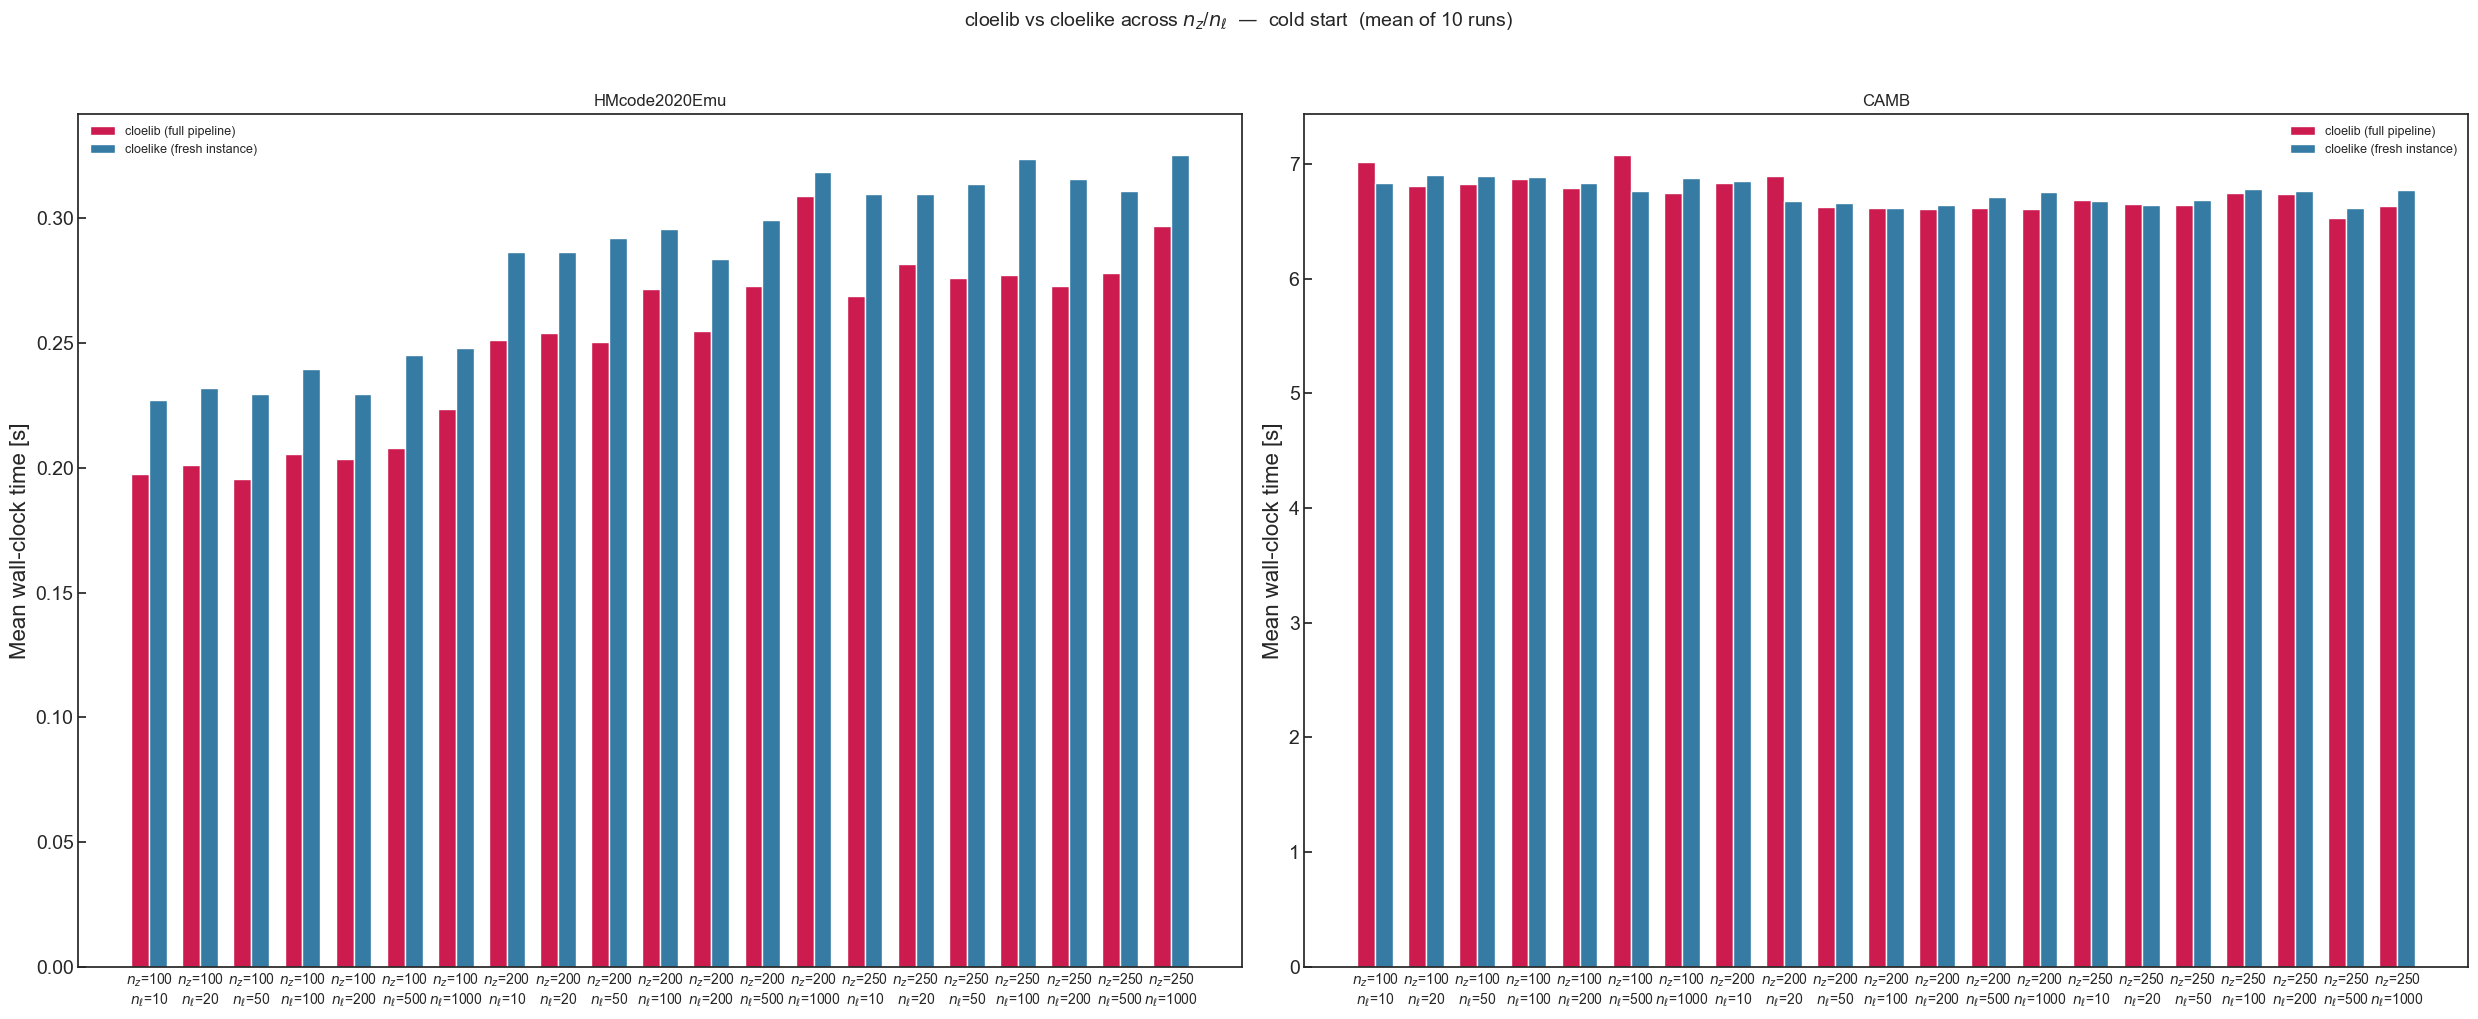

In [23]:
configs = [(nz, nell) for nz in nz_values_sweep for nell in nell_values_sweep]
config_labels = [f'$n_z$={nz}\n$n_\\ell$={nell}' for nz, nell in configs]
x = np.arange(len(configs))
width = 0.35

# Cold-start comparison: full rebuild each call (both sides) -- the realistic per-call cost
# when a sampler visits a brand-new point in cosmology.
fig, axes = plt.subplots(1, 2, figsize=(25, 10))
for ax, engine_name in zip(axes, engines):
    direct_vals = [results_sweep[engine_name][cfg]['direct_full'] for cfg in configs]
    wrapped_vals = [results_sweep[engine_name][cfg]['wrapped_cold'] for cfg in configs]

    ax.bar(x - width / 2, direct_vals, width, label='cloelib (full pipeline)',
           color=sns.color_palette("rocket", 3)[1])
    ax.bar(x + width / 2, wrapped_vals, width, label='cloelike (fresh instance)',
           color=sns.color_palette("mako", 3)[1])
    ax.set_xticks(x)
    ax.set_xticklabels(config_labels, fontsize=10)
    ax.set_ylabel('Mean wall-clock time [s]')
    ax.set_title(engine_name)
    ax.legend(frameon=False, fontsize=9)
    ax.tick_params(axis='both', which='both', direction='in')

plt.suptitle(f'cloelib vs cloelike across $n_z$/$n_\\ell$  —  cold start  (mean of {N_REPEAT_SWEEP} runs)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('time_comparison_cloelib_vs_cloelike_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

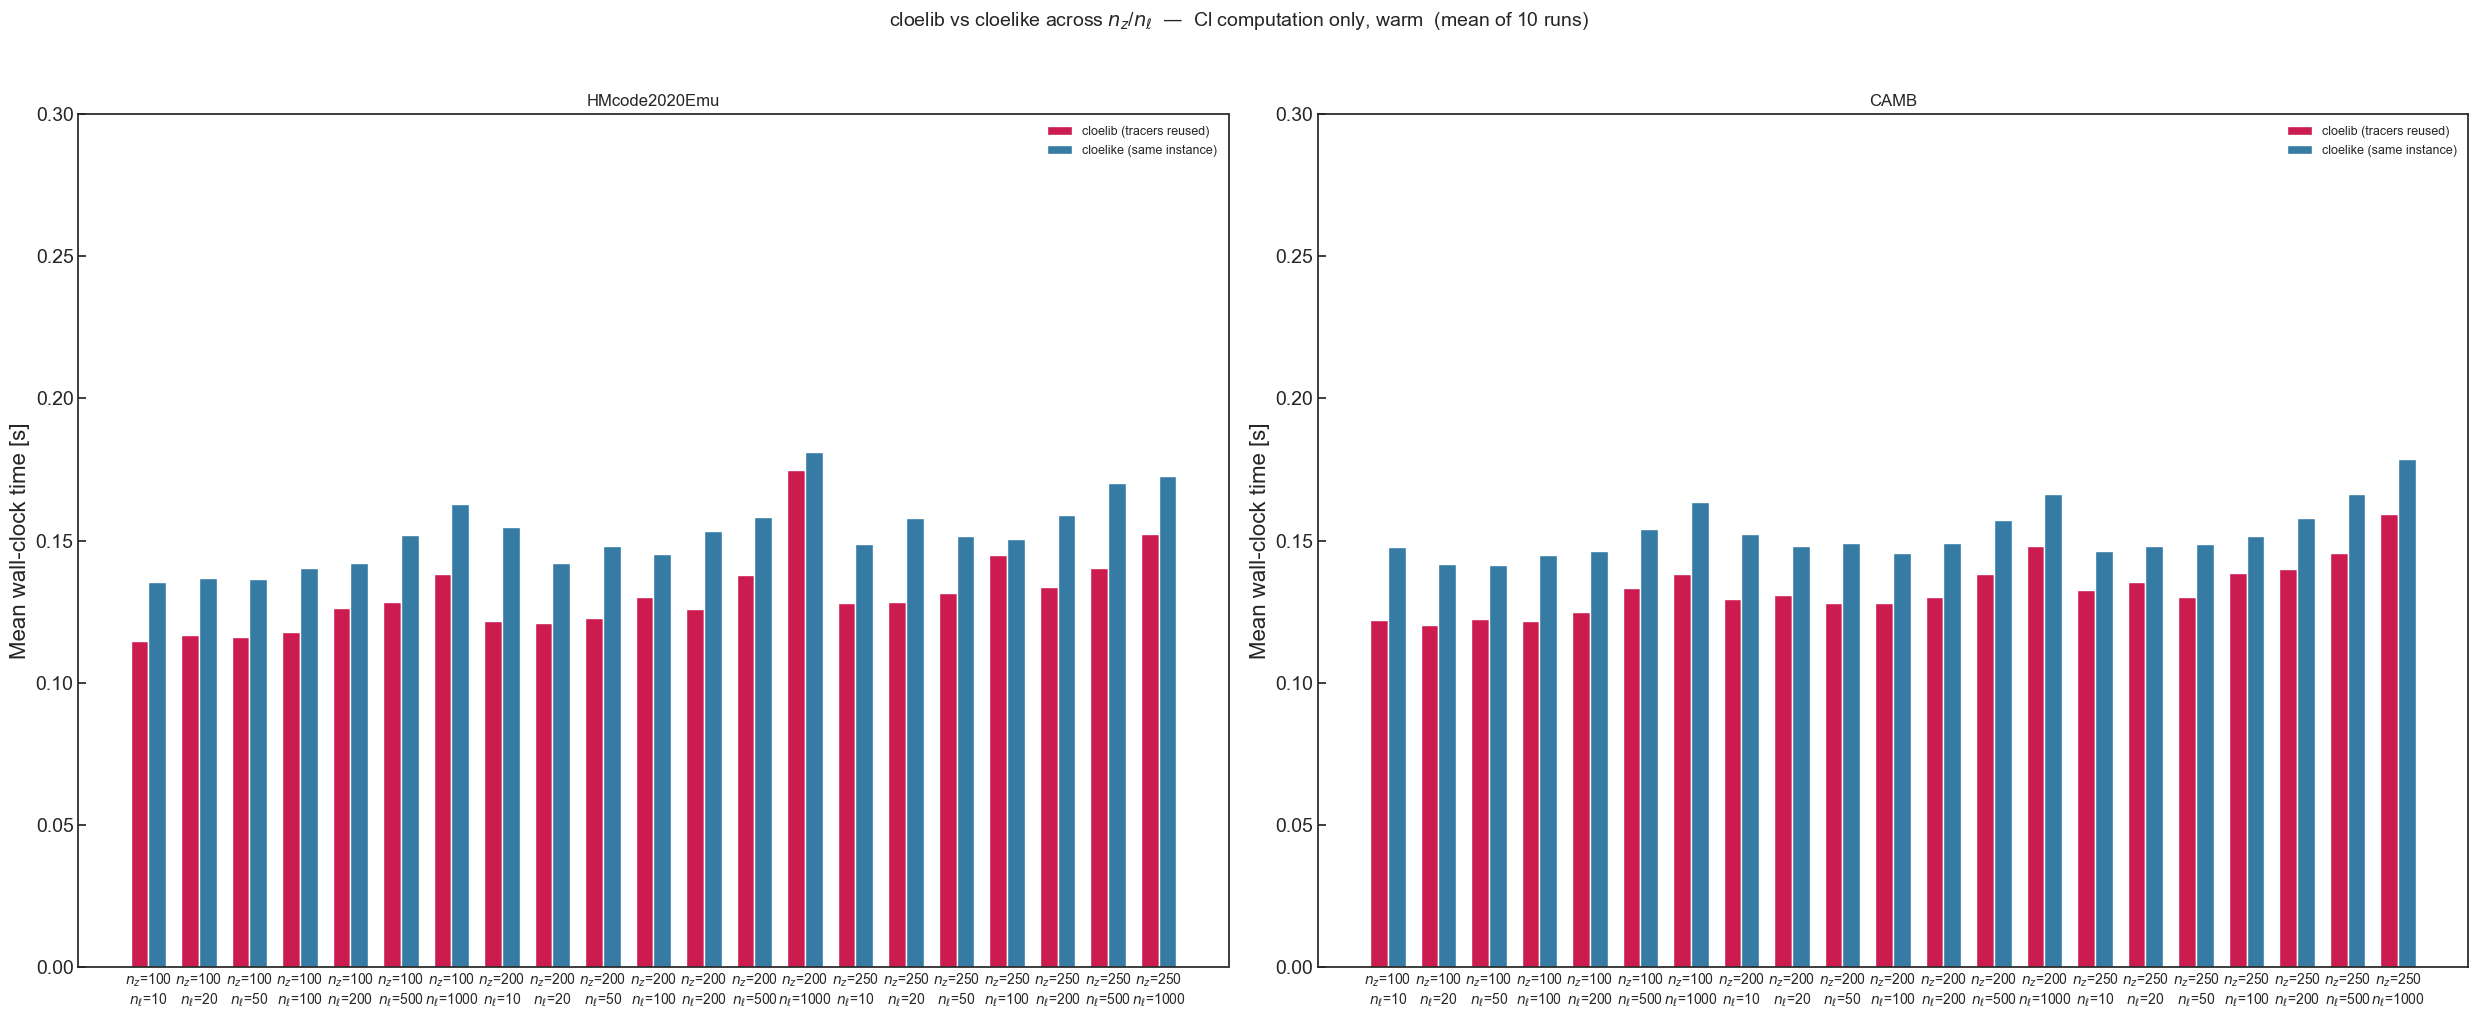

In [24]:
# Warm comparison: perturbations/tracers (and, for cloelike, the whole instance) are already
# built and cached -- this isolates the Cl computation itself, without construction overhead.
fig, axes = plt.subplots(1, 2, figsize=(25, 10))
for ax, engine_name in zip(axes, engines):
    direct_vals = [results_sweep[engine_name][cfg]['direct_reused'] for cfg in configs]
    wrapped_vals = [results_sweep[engine_name][cfg]['wrapped_warm'] for cfg in configs]

    ax.bar(x - width / 2, direct_vals, width, label='cloelib (tracers reused)',
           color=sns.color_palette("rocket", 3)[1])
    ax.bar(x + width / 2, wrapped_vals, width, label='cloelike (same instance)',
           color=sns.color_palette("mako", 3)[1])
    ax.set_xticks(x)
    ax.set_xticklabels(config_labels, fontsize=10)
    ax.set_ylabel('Mean wall-clock time [s]')
    ax.set_title(engine_name)
    ax.legend(frameon=False, fontsize=9)
    ax.tick_params(axis='both', which='both', direction='in')
    ax.set_ylim(0, 0.3)  # avoid negative y-axis due to small noise in mean timings

plt.suptitle(f'cloelib vs cloelike across $n_z$/$n_\\ell$  —  Cl computation only, warm  (mean of {N_REPEAT_SWEEP} runs)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('time_comparison_cloelib_vs_cloelike_sweep_warm.png', dpi=150, bbox_inches='tight')
plt.show()

## NLA vs TATT — computational cost

TATT computes its ten one-loop kernels via FAST-PT once per k-grid (`PBJTATTLoopComputer`, cached and reused across `get_Cl` calls that share the same k-grid - see its docstring); NLA has no such setup step. This section times both models **cold** (a fresh `ShearTracer` + `PBJTATTLoopComputer` and the first `get_Cl` call, so TATT pays the full FAST-PT cost every time) and **warm** (the same tracer/engine reused across repeated `get_Cl` calls on the same $\ell$/$k$ grid, so TATT's kernels are already cached) across a sweep of $n_\ell$, to characterize that up-front cost and how well it amortizes.


In [11]:
from cloelib.observables.photo.shear import PBJTATTLoopComputer

nuisance_she_tatt = {**nuisance_she, "A2IA": 0.40, "bTA": -0.83, "Eta2IA": 2.69, "z0IA": 0.62}


def build_she_tracer(ia_model, loop_computer=None):
    kwargs = dict(
        perturbations=nonlin_pert, dndz=my_dndz_norm, z=zs,
        nuisance_params=nuisance_she_tatt if ia_model == "TATT" else nuisance_she,
        ia_model=ia_model,
    )
    if loop_computer is not None:
        kwargs["tatt_loop_computer"] = loop_computer
    return ShearTracer(**kwargs)


N_REPEAT_IA = 3
nell_values_ia = [20, 100, 500, 1000]

results_ia = {"NLA": {"cold": {}, "warm": {}}, "TATT": {"cold": {}, "warm": {}}}

for nell in nell_values_ia:
    ells_ia = np.unique(np.geomspace(2, 2999, nell).astype(int))

    # NLA: no setup-cost distinction expected, but timed the same way for a fair comparison
    def _nla_cold():
        tr = build_she_tracer("NLA")
        return AngularTwoPoint(tr, tr).get_Cl(ells_ia, 0, nonlin_pert.k)
    t_nla_cold = timeit.repeat(_nla_cold, repeat=N_REPEAT_IA, number=1)
    results_ia["NLA"]["cold"][nell] = np.median(t_nla_cold)

    tr_nla_warm = build_she_tracer("NLA")
    tp_nla_warm = AngularTwoPoint(tr_nla_warm, tr_nla_warm)
    _ = tp_nla_warm.get_Cl(ells_ia, 0, nonlin_pert.k)  # warm-up, untimed
    t_nla_warm = timeit.repeat(lambda: tp_nla_warm.get_Cl(ells_ia, 0, nonlin_pert.k),
                                repeat=N_REPEAT_IA, number=1)
    results_ia["NLA"]["warm"][nell] = np.median(t_nla_warm)

    # TATT: cold = fresh loop_computer (no cache) + first get_Cl call on this k-grid
    def _tatt_cold():
        tr = build_she_tracer("TATT", PBJTATTLoopComputer(nonlin_pert))
        return AngularTwoPoint(tr, tr).get_Cl(ells_ia, 0, nonlin_pert.k)
    t_tatt_cold = timeit.repeat(_tatt_cold, repeat=N_REPEAT_IA, number=1)
    results_ia["TATT"]["cold"][nell] = np.median(t_tatt_cold)

    tr_tatt_warm = build_she_tracer("TATT", PBJTATTLoopComputer(nonlin_pert))
    tp_tatt_warm = AngularTwoPoint(tr_tatt_warm, tr_tatt_warm)
    _ = tp_tatt_warm.get_Cl(ells_ia, 0, nonlin_pert.k)  # warm-up: computes + caches the FAST-PT kernels
    t_tatt_warm = timeit.repeat(lambda: tp_tatt_warm.get_Cl(ells_ia, 0, nonlin_pert.k),
                                 repeat=N_REPEAT_IA, number=1)
    results_ia["TATT"]["warm"][nell] = np.median(t_tatt_warm)

    print(f"n_ell={nell:5d} | NLA  cold {results_ia['NLA']['cold'][nell]:.3f}s  warm {results_ia['NLA']['warm'][nell]:.4f}s | "
          f"TATT cold {results_ia['TATT']['cold'][nell]:.3f}s  warm {results_ia['TATT']['warm'][nell]:.4f}s  "
          f"(TATT/NLA warm ratio: {results_ia['TATT']['warm'][nell]/results_ia['NLA']['warm'][nell]:.2f}x)")

print("\nNLA vs TATT sweep complete.")


n_ell=   20 | NLA  cold 0.106s  warm 0.0568s | TATT cold 0.338s  warm 0.0961s  (TATT/NLA warm ratio: 1.69x)


n_ell=  100 | NLA  cold 0.093s  warm 0.0779s | TATT cold 0.392s  warm 0.0795s  (TATT/NLA warm ratio: 1.02x)


n_ell=  500 | NLA  cold 0.061s  warm 0.1068s | TATT cold 0.432s  warm 0.0934s  (TATT/NLA warm ratio: 0.87x)


n_ell= 1000 | NLA  cold 0.071s  warm 0.0676s | TATT cold 0.440s  warm 0.1233s  (TATT/NLA warm ratio: 1.82x)

NLA vs TATT sweep complete.


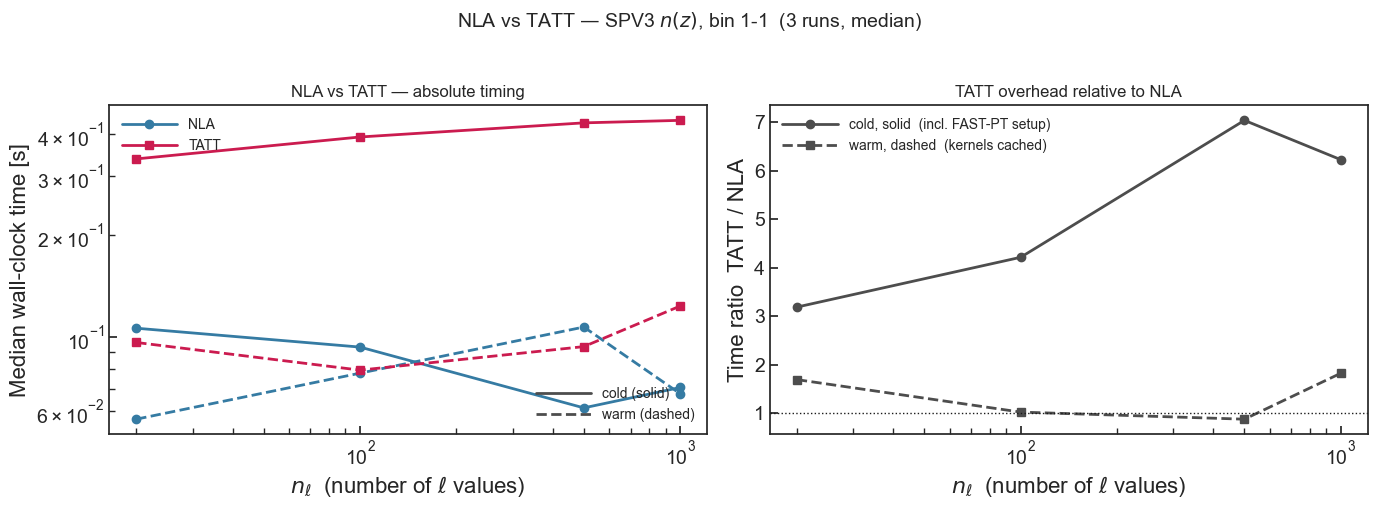

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax_t, ax_r = axes
nell_arr_ia = np.array(nell_values_ia)

pal = {"NLA": sns.color_palette("mako", 3)[1], "TATT": sns.color_palette("rocket", 3)[1]}
for model, marker in [("NLA", 'o'), ("TATT", 's')]:
    cold = np.array([results_ia[model]["cold"][n] for n in nell_values_ia])
    warm = np.array([results_ia[model]["warm"][n] for n in nell_values_ia])
    ax_t.plot(nell_arr_ia, cold, color=pal[model], lw=2, marker=marker)
    ax_t.plot(nell_arr_ia, warm, color=pal[model], lw=2, marker=marker, ls='--')

ax_t.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_t.set_ylabel('Median wall-clock time [s]')
ax_t.set_title('NLA vs TATT — absolute timing')
ax_t.set_xscale('log'); ax_t.set_yscale('log')
cold_warm_legends(ax_t, [('NLA', pal['NLA'], 'o'), ('TATT', pal['TATT'], 's')], fontsize=10)
ax_t.tick_params(axis='both', which='both', direction='in')

ratio_cold = np.array([results_ia["TATT"]["cold"][n] / results_ia["NLA"]["cold"][n] for n in nell_values_ia])
ratio_warm = np.array([results_ia["TATT"]["warm"][n] / results_ia["NLA"]["warm"][n] for n in nell_values_ia])
ax_r.plot(nell_arr_ia, ratio_cold, color='0.3', lw=2, marker='o', label='cold, solid  (incl. FAST-PT setup)')
ax_r.plot(nell_arr_ia, ratio_warm, color='0.3', lw=2, marker='s', ls='--', label='warm, dashed  (kernels cached)')
ax_r.axhline(1.0, color='k', lw=1, ls=':')
ax_r.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_r.set_ylabel('Time ratio  TATT / NLA')
ax_r.set_title('TATT overhead relative to NLA')
ax_r.set_xscale('log')
ax_r.legend(fontsize=10, frameon=False)
ax_r.tick_params(axis='both', which='both', direction='in')

plt.suptitle(f'NLA vs TATT — SPV3 $n(z)$, bin 1-1  ({N_REPEAT_IA} runs, median)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('time_comparison_NLA_vs_TATT.png', dpi=150, bbox_inches='tight')
plt.show()


TATT's **cold** cost is dominated by the FAST-PT one-loop kernel computation in `PBJTATTLoopComputer` - roughly 3-7x slower than NLA's cold call, and essentially flat across $n_\ell$ (the FAST-PT cost depends on the $k$-grid, not $\ell$). Once **warm** (the same `PBJTATTLoopComputer` instance reused, so its kernels are cached - see its docstring), that gap collapses to roughly 0.9-1.8x (i.e. close to NLA, within run-to-run noise): the residual overhead is just TATT's extra one-loop terms in the Limber sum itself (ten kernels for II vs none for NLA), not the FAST-PT call. In other words, TATT's real cost is a one-time, $\ell$-independent setup per $k$-grid - cheap to amortize across many `get_Cl` calls on that grid (e.g. many $\ell$ or bin combinations, or repeated calls in a sampler that doesn't change the $k$-grid), expensive if paid on every single call.


## TATT: cloelib vs pyccl — which is faster?

`pyccl` also supports TATT, but not as a one-line option the way NLA is above (`WeakLensingTracer(ia_bias=...)`): it goes through the general perturbation-theory machinery in `pyccl.nl_pt` - `PTIntrinsicAlignmentTracer(c1, c2, cdelta)` for the bias functions and `EulerianPTCalculator.get_biased_pk2d(...)` for the resulting $P_{\delta I}(k,z)$/$P_{II}(k,z)$ - then a manual sum of the GG + GI + IG + II pieces (`WeakLensingTracer(has_shear=..., ia_bias=...)` can only bundle a *single* kernel + one shared power spectrum, which is enough for NLA's simple $C_1(z)\,P_{\rm dd}$ scaling but not for TATT's distinct per-term $k$-shapes).

**It's not actually a different PT engine**: `EulerianPTCalculator` does `import fastpt as fpt` internally and calls `.IA_ta()`/`.IA_tt()`/`.IA_mix()` - the exact same `fast-pt` methods `PBJTATTLoopComputer` calls for `cloelib`. So an initial cold-timing comparison at each library's own *default* resolution isn't a fair one: it turned out to mostly measure a $k$-grid-size difference, not a computational one - `PBJTATTLoopComputer` builds its FAST-PT grid to match whichever `perturbations.k` was passed in (597 points here, from `HMemuNonLinearPerturbations`'s own native grid), while `EulerianPTCalculator` defaults to a coarser 120-point grid. The cells below fix that: `EulerianPTCalculator` is built with `log10k_min`/`log10k_max`/`nk_per_decade` chosen to reproduce the same 596-597-point grid `cloelib` actually uses, so both libraries hand FAST-PT the same amount of work.

$C_1(z)$/$C_2(z)$/$C_{1\delta}(z)$ are computed with the *exact same formulas* `TATTContribution` uses (see its docstring), evaluated with `cosmo_ccl`'s own $\Omega_m$/growth factor. **This section is still a timing comparison, not a precision cross-validation one**: a reduction check (TATT with $A_2=b_{TA}=0$, which should collapse to pure NLA) shows the two pipelines agree at low $\ell$ but diverge by up to ~60% at high $\ell$, unchanged by the $k$-grid matching above - so it isn't a resolution/extrapolation effect either, and remains a real open item for anyone wanting to trust absolute pyccl-TATT numbers here. It doesn't affect the timing comparison below.


In [13]:
import pyccl.nl_pt as pt

first_key = list(dndz_norm)[0]
dndz_bin1 = (z_nz, dndz_norm[first_key])

# C1(z)/C2(z)/C1delta(z), matching TATTContribution's formulas exactly (see its
# docstring in cloelib/observables/photo/shear.py) - same nuisance values used in
# the cloelib TATT section above.
Omega_m0_ccl = cosmo_ccl['Omega_c'] + cosmo_ccl['Omega_b']
Dz_ccl = cosmo_ccl.growth_factor(1.0 / (1.0 + z_nz))

C1_z = -AIA * CIA * Omega_m0_ccl * ((1 + z_nz) / (1 + 0.62)) ** EtaIA / Dz_ccl
C2_z = 5 * 0.40 * CIA * Omega_m0_ccl / Dz_ccl ** 2 * ((1 + z_nz) / (1 + 0.62)) ** 2.69
C1delta_z = -0.83 * C1_z

# Match EulerianPTCalculator's FAST-PT k-grid to the one PBJTATTLoopComputer actually
# builds for this same nonlin_pert.k (597 points, 1e-4..500 h/Mpc, log-uniform) - see
# the markdown above. Without this, the two libraries would be handing FAST-PT very
# different amounts of work, and any timing comparison would mostly measure that.
LOG10K_MIN, LOG10K_MAX = -4, np.log10(500)
NK_PER_DECADE = 89  # -> 596 points, matches cloelib's 597-point k_win


def build_ccl_tatt(c1z, c2z, cdz):
    """Build the (lensing, IA) tracer pair + their biased P(k,z) for a TATT Cl."""
    ia_tracer_pt = pt.PTIntrinsicAlignmentTracer(c1=(z_nz, c1z), c2=(z_nz, c2z), cdelta=(z_nz, cdz))
    matter_tracer_pt = pt.PTMatterTracer()
    ptc = pt.EulerianPTCalculator(
        with_NC=False, with_IA=True, with_matter_1loop=True, cosmo=cosmo_ccl,
        log10k_min=LOG10K_MIN, log10k_max=LOG10K_MAX, nk_per_decade=NK_PER_DECADE,
    )
    pk_gi = ptc.get_biased_pk2d(matter_tracer_pt, tracer2=ia_tracer_pt)
    pk_ii = ptc.get_biased_pk2d(ia_tracer_pt, tracer2=ia_tracer_pt)

    G = ccl.WeakLensingTracer(cosmo_ccl, dndz=dndz_bin1, has_shear=True, ia_bias=None)
    I = ccl.WeakLensingTracer(cosmo_ccl, dndz=dndz_bin1, has_shear=False,
                               ia_bias=(z_nz, np.ones_like(z_nz)), use_A_ia=False)
    return G, I, pk_gi, pk_ii


def cl_ee_tatt_ccl(ells_cfg, c1z, c2z, cdz):
    G, I, pk_gi, pk_ii = build_ccl_tatt(c1z, c2z, cdz)
    return (ccl.angular_cl(cosmo_ccl, G, G, ells_cfg)
            + ccl.angular_cl(cosmo_ccl, G, I, ells_cfg, p_of_k_a=pk_gi)
            + ccl.angular_cl(cosmo_ccl, I, G, ells_cfg, p_of_k_a=pk_gi)
            + ccl.angular_cl(cosmo_ccl, I, I, ells_cfg, p_of_k_a=pk_ii))


# Sanity: verify the matched grid really has ~597 points
_check = pt.EulerianPTCalculator(with_IA=True, log10k_min=LOG10K_MIN, log10k_max=LOG10K_MAX,
                                  nk_per_decade=NK_PER_DECADE)
print("matched FAST-PT k-grid length:", len(_check.k_s), " (cloelib's is 597)")

# Reduction check: A2=bTA=0 should collapse to plain NLA (same C1(z), no C2/C1delta terms)
ells_check = np.unique(np.logspace(1, np.log10(2999), 20).astype(int))
cl_tatt_zero = cl_ee_tatt_ccl(ells_check, C1_z, np.zeros_like(C2_z), np.zeros_like(C1delta_z))

ia_bias_nla = AIA * CIA * (1.0 + z_nz) ** EtaIA
we_nla = ccl.WeakLensingTracer(cosmo_ccl, dndz=dndz_bin1, ia_bias=(z_nz, ia_bias_nla))
cl_nla_native = ccl.angular_cl(cosmo_ccl, we_nla, we_nla, ells_check)

print("max |TATT(A2=bTA=0) vs native pyccl NLA - 1|: %.1f%%"
      % (np.max(np.abs(cl_tatt_zero / cl_nla_native - 1)) * 100))
print("(unchanged by the k-grid matching above - not a resolution effect; see markdown)")


matched FAST-PT k-grid length: 596  (cloelib's is 597)


max |TATT(A2=bTA=0) vs native pyccl NLA - 1|: 59.5%
(unchanged by the k-grid matching above - not a resolution effect; see markdown)


In [14]:
results_pyccl_tatt = {"cold": {}, "warm": {}}

for nell in nell_values_ia:  # reuses the sweep grid from the cloelib TATT section above
    ells_ia = np.unique(np.geomspace(2, 2999, nell).astype(int))

    def _pyccl_tatt_cold():
        return cl_ee_tatt_ccl(ells_ia, C1_z, C2_z, C1delta_z)
    t_cold = timeit.repeat(_pyccl_tatt_cold, repeat=N_REPEAT_IA, number=1)
    results_pyccl_tatt["cold"][nell] = np.median(t_cold)

    G_w, I_w, pk_gi_w, pk_ii_w = build_ccl_tatt(C1_z, C2_z, C1delta_z)
    def _pyccl_tatt_warm():
        cl_gg = ccl.angular_cl(cosmo_ccl, G_w, G_w, ells_ia)
        cl_gi = ccl.angular_cl(cosmo_ccl, G_w, I_w, ells_ia, p_of_k_a=pk_gi_w)
        cl_ig = ccl.angular_cl(cosmo_ccl, I_w, G_w, ells_ia, p_of_k_a=pk_gi_w)
        cl_ii = ccl.angular_cl(cosmo_ccl, I_w, I_w, ells_ia, p_of_k_a=pk_ii_w)
        return cl_gg + cl_gi + cl_ig + cl_ii
    _ = _pyccl_tatt_warm()  # untimed warm-up
    t_warm = timeit.repeat(_pyccl_tatt_warm, repeat=N_REPEAT_IA, number=1)
    results_pyccl_tatt["warm"][nell] = np.median(t_warm)

    print(f"n_ell={nell:5d} | pyccl TATT (matched res)  cold {results_pyccl_tatt['cold'][nell]:.3f}s  "
          f"warm {results_pyccl_tatt['warm'][nell]:.4f}s")


n_ell=   20 | pyccl TATT (matched res)  cold 0.328s  warm 0.0080s


n_ell=  100 | pyccl TATT (matched res)  cold 0.360s  warm 0.0211s


n_ell=  500 | pyccl TATT (matched res)  cold 0.477s  warm 0.0790s


n_ell= 1000 | pyccl TATT (matched res)  cold 0.527s  warm 0.1485s


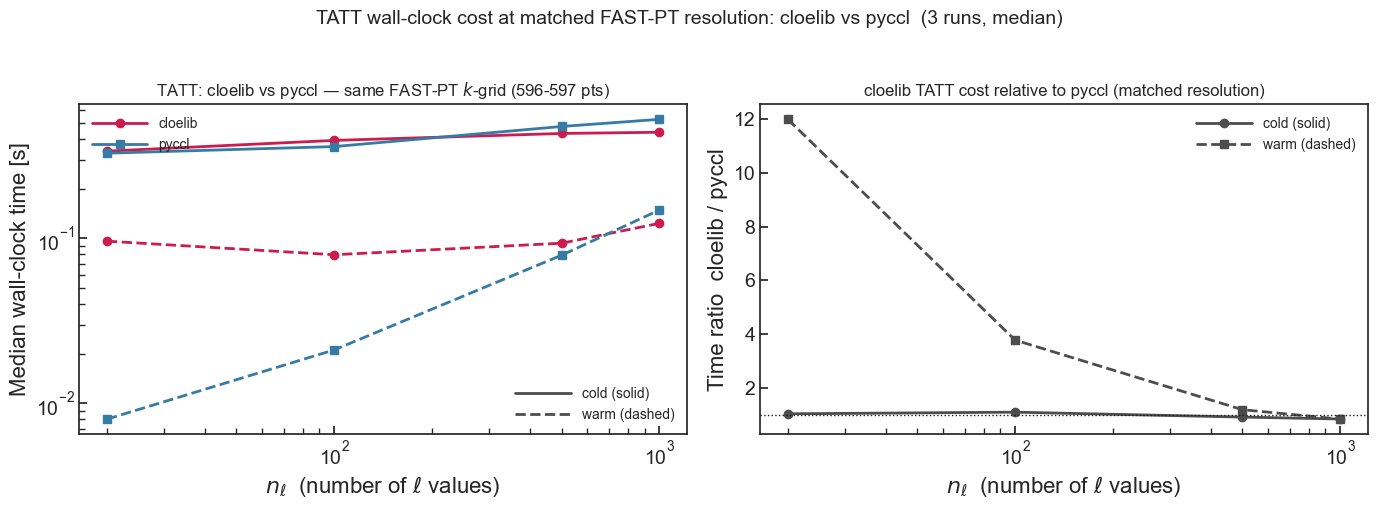

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax_t, ax_r = axes
nell_arr = np.array(nell_values_ia)

pal = {"cloelib": sns.color_palette("rocket", 3)[1], "pyccl": sns.color_palette("mako", 3)[1]}
for label, data, marker in [("cloelib", results_ia["TATT"], 'o'), ("pyccl", results_pyccl_tatt, 's')]:
    cold = np.array([data["cold"][n] for n in nell_values_ia])
    warm = np.array([data["warm"][n] for n in nell_values_ia])
    ax_t.plot(nell_arr, cold, color=pal[label], lw=2, marker=marker)
    ax_t.plot(nell_arr, warm, color=pal[label], lw=2, marker=marker, ls='--')

ax_t.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_t.set_ylabel('Median wall-clock time [s]')
ax_t.set_title('TATT: cloelib vs pyccl — same FAST-PT $k$-grid (596-597 pts)')
ax_t.set_xscale('log'); ax_t.set_yscale('log')
cold_warm_legends(ax_t, [('cloelib', pal['cloelib'], 'o'), ('pyccl', pal['pyccl'], 's')], fontsize=10)
ax_t.tick_params(axis='both', which='both', direction='in')

ratio_cold = np.array([results_ia["TATT"]["cold"][n] / results_pyccl_tatt["cold"][n] for n in nell_values_ia])
ratio_warm = np.array([results_ia["TATT"]["warm"][n] / results_pyccl_tatt["warm"][n] for n in nell_values_ia])
ax_r.plot(nell_arr, ratio_cold, color='0.3', lw=2, marker='o', label='cold (solid)')
ax_r.plot(nell_arr, ratio_warm, color='0.3', lw=2, marker='s', ls='--', label='warm (dashed)')
ax_r.axhline(1.0, color='k', lw=1, ls=':')
ax_r.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_r.set_ylabel('Time ratio  cloelib / pyccl')
ax_r.set_title('cloelib TATT cost relative to pyccl (matched resolution)')
ax_r.set_xscale('log')
ax_r.legend(fontsize=10, frameon=False)
ax_r.tick_params(axis='both', which='both', direction='in')

plt.suptitle('TATT wall-clock cost at matched FAST-PT resolution: cloelib vs pyccl  (%d runs, median)' % N_REPEAT_IA,
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('time_comparison_cloelib_vs_pyccl_TATT.png', dpi=150, bbox_inches='tight')
plt.show()


**At matched FAST-PT resolution, the cold cost is essentially the same in both libraries.** Cold: ~0.8-1.1x pyccl (down from ~3-4.5x at each library's own default resolution) - both are dominated by the *same* FAST-PT call, and what remains is wrapper/setup overhead (tracer construction, `WeakLensingTracer`/`ShearTracer` setup, `AngularTwoPoint` bookkeeping), not a difference in the PT computation itself. Warm: still up to ~12x slower at small $n_\ell$, reaching parity (~0.8x) by $n_\ell$=1000 - resolution-independent, since a cached `Pk2D`/kernel-cache pays no further FAST-PT cost regardless of how it was built. The two warm scalings differ structurally: pyccl's `angular_cl` is called four times per bin pair (GG/GI/IG/II) and its cost grows with $n_\ell$ accordingly, while cloelib's jitted `Cl_integration` amortizes the $\ell$ loop far more efficiently once compiled - a large-$n_\ell$, many-bin-pair workload (the realistic 3x2pt case) favors cloelib more than this single-bin, $n_\ell$-swept toy problem suggests.


## Why doesn't cloelib's NLA speed advantage over pyccl carry over to TATT?

The TATT comparison above found cloelib *slower* than pyccl, even at matched FAST-PT resolution - which is surprising if cloelib is generally the faster library. It is, but not for the reason it might seem: **cloelib's NLA advantage over pyccl is a batching advantage, not a faster Limber integral.** `AngularTwoPoint.get_Cl` computes the entire `(n_ell, n_bins, n_bins)` $C_\ell$ tensor in one jitted, vectorized XLA call; `ccl.angular_cl` has no native multi-tracer batching, so a full tomographic computation calls it once per bin pair. The cell below makes this concrete on the same 13-bin SPV3 $n(z)$ used throughout this notebook (`tracer_she_cl`/`tracers_she_ccl` from the cells above), for SHE-SHE alone (91 bin pairs):


In [30]:
results_multibin = {"cloelib": {}, "pyccl": {}}
N_REPEAT_MULTIBIN = 3
nell_values_multibin = [20, 100, 500]

for nell in nell_values_multibin:
    ells_mb = np.unique(np.geomspace(2, 2999, nell).astype(int))

    _ = tp_ee.get_Cl(ells_mb, 0, nonlin_pert.k)  # warm-up
    t_cl = timeit.repeat(lambda: tp_ee.get_Cl(ells_mb, 0, nonlin_pert.k),
                          repeat=N_REPEAT_MULTIBIN, number=1)
    results_multibin["cloelib"][nell] = np.median(t_cl)

    def _ccl_all_pairs():
        out = {}
        for i in range(n_bins):
            for j in range(i, n_bins):
                out[i, j] = ccl.angular_cl(cosmo_ccl, tracers_she_ccl[i], tracers_she_ccl[j],
                                            ells_mb, limber_integration_method='spline')
        return out
    _ = _ccl_all_pairs()  # warm-up
    t_ccl = timeit.repeat(_ccl_all_pairs, repeat=N_REPEAT_MULTIBIN, number=1)
    results_multibin["pyccl"][nell] = np.median(t_ccl)

    n_pairs = n_bins * (n_bins + 1) // 2
    print(f"n_ell={nell:5d}  ({n_pairs} bin pairs) | "
          f"cloelib (1 call) {results_multibin['cloelib'][nell]:.4f}s   "
          f"pyccl ({n_pairs} calls) {results_multibin['pyccl'][nell]:.4f}s   "
          f"ratio pyccl/cloelib: {results_multibin['pyccl'][nell]/results_multibin['cloelib'][nell]:.1f}x")


n_ell=   20  (91 bin pairs) | cloelib (1 call) 0.0484s   pyccl (91 calls) 0.0524s   ratio pyccl/cloelib: 1.1x


n_ell=  100  (91 bin pairs) | cloelib (1 call) 0.0526s   pyccl (91 calls) 0.1632s   ratio pyccl/cloelib: 3.1x


n_ell=  500  (91 bin pairs) | cloelib (1 call) 0.0531s   pyccl (91 calls) 0.5287s   ratio pyccl/cloelib: 10.0x


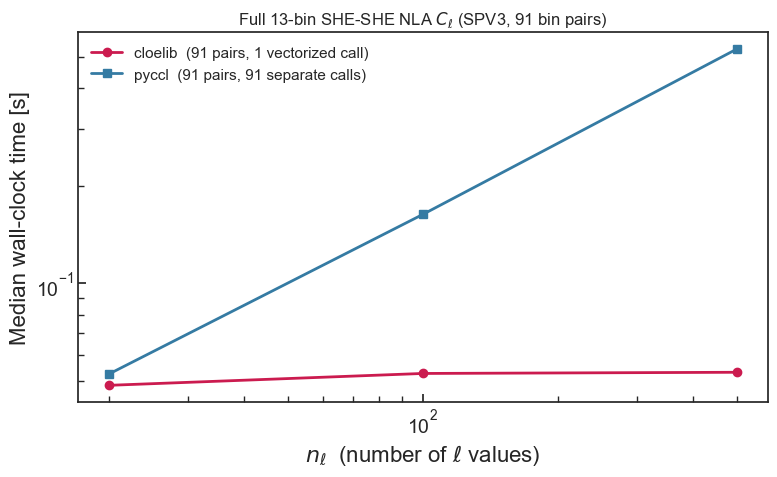

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
nell_arr_mb = np.array(nell_values_multibin)
cl_t = np.array([results_multibin["cloelib"][n] for n in nell_values_multibin])
pc_t = np.array([results_multibin["pyccl"][n] for n in nell_values_multibin])

ax.plot(nell_arr_mb, cl_t, color=sns.color_palette("rocket", 3)[1], lw=2, marker='o',
        label='cloelib  (91 pairs, 1 vectorized call)')
ax.plot(nell_arr_mb, pc_t, color=sns.color_palette("mako", 3)[1], lw=2, marker='s',
        label='pyccl  (91 pairs, 91 separate calls)')
ax.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax.set_ylabel('Median wall-clock time [s]')
ax.set_title('Full 13-bin SHE-SHE NLA $C_\\ell$ (SPV3, 91 bin pairs)')
ax.set_xscale('log'); ax.set_yscale('log')
ax.legend(fontsize=11, frameon=False)
ax.tick_params(axis='both', which='both', direction='in')
plt.tight_layout()
plt.savefig('time_comparison_NLA_multibin_batching.png', dpi=150, bbox_inches='tight')
plt.show()


cloelib stays essentially flat (~0.05s) as $n_\ell$ grows - the whole 91-pair tensor is one compiled XLA call, so more $\ell$ values just mean a bigger array inside the same call. pyccl scales up to ~10x slower at $n_\ell$=500 - 91 separate Python/C-level `angular_cl` calls, each paying its own per-$\ell$ integration cost with nothing shared across bin pairs.

**This is exactly the advantage TATT doesn't get to keep, on either side:**

- In **cloelib**, going NLA→TATT doesn't touch this batching at all - the generalized engine just adds a few more `(c1, c2)` contribution-pair terms (II gets ~10 kernel terms, GI gets ~4) *inside the same single vectorized call*. That's why the cloelib-only section further above found TATT/NLA warm ratios of only ~0.9-1.8x: cheap, because it's not creating new calls, just a few more terms in an already-batched sum.
- In **pyccl**, NLA's competitiveness (relative to its own lack of cross-bin batching) rested on a shortcut: `WeakLensingTracer(ia_bias=...)` folds lensing and IA into one combined kernel against one shared power spectrum, because NLA's IA term is just $C_1(z)$ scaling the matter $P(k,z)$ - one `angular_cl` call per bin pair, same as pure lensing. TATT can't use that shortcut: GG, GI, IG, II have genuinely different $k$-shapes, so it needs **4 separate `angular_cl` calls per bin pair** instead of 1. pyccl's already-absent cross-bin batching is now paid 4 times over per bin pair too.

Net effect: cloelib's real advantage (batching over bin pairs) is untouched by TATT; pyccl's real disadvantage (no batching over bin pairs) gets compounded by TATT's extra per-pair calls. That's the whole story behind the matched-resolution TATT result above looking so different from the NLA picture here.


## Full 3x2pt: cloelib vs pyccl (TATT + non-linear galaxy bias)

Combining both advanced models from above: `ShearTracer(ia_model="TATT")` for cosmic shear intrinsic alignments and `PositionsTracer(galaxy_bias_model="nonlinear")` (McDonald & Roy 2009 + a $b_{k^2}$ counterterm) for galaxy clustering, for the full photometric 3x2pt ($C_\ell^{\rm gg}$ + $C_\ell^{\rm gE}$ + $C_\ell^{\rm EE}$). As with the TATT-only section above, this is a **timing** comparison, not a precision cross-validation one: `cloelib` uses `HMemuNonLinearPerturbations` for the nonlinear matter power spectrum throughout this notebook, `pyccl` uses `halofit` (see the notebook intro) - the two codes' *absolute* $C_\ell$ values are never expected to match exactly here, independent of the bias/IA modelling.

`pyccl.nl_pt` happens to expose the *same* $(b_1, b_2, b_s, b_{3\rm nl}, b_{k^2})$ basis `NonLinearGalaxyBiasContribution` uses (`pt.PTNumberCountsTracer`) - no basis conversion needed, unlike production CLOE's own Lagrangian $b_{\mathcal G_2}/b_{\Gamma_3}$ basis (see that class's docstring). `EulerianPTCalculator.get_biased_pk2d` supplies $P_{gg}$ and $P_{g\delta}$ (galaxy-lensing) in the same call as the $P_{\delta I}$/$P_{II}$ terms the TATT section above already builds - plus $P_{gI}$ (galaxy-intrinsic), which pyccl's own `_get_pgi` restricts to *linear* bias only, exactly matching `NonLinearGalaxyBiasContribution`'s own IA-pairing convention (see its docstring).

FAST-PT grids: `PBJTATTLoopComputer` uses `len(perturbations.k)` = 597 points, which the matched pyccl grid (596) reproduces. `PBJNonlinearBiasLoopComputer` enforces a minimum of 100 points per decade, so its bias kernels use 670 points over the same range (needed for the $\sigma_3^2 P_{\rm lin}$ kernel's accuracy, see `playground/validation/validation_ccl_nonlinear_bias.ipynb`). pyccl computes both sets of kernels on its single 596-point grid.

In [16]:
# Non-linear galaxy bias - same (b1, b2, bs, b3nl, bk2) for every bin
# (matching this notebook's existing "flat bias" convention, e.g. nuisance_pos's
# poly0=1.0 above) - illustrative values, no fiducial table to draw them from.
b1_gc, b2_gc, bs_gc, b3nl_gc, bk2_gc = 1.0, 0.5, -0.3, 0.2, 0.1


def build_ccl_full_3x2pt(c1z, c2z, cdz):
    """Build the (N, G, I) tracers + their five biased P(k,z)'s for a full
    GC-GC/GC-WL/WL-WL Cl (McDonald & Roy + bk2 galaxy bias, TATT IA), bin 1.
    Reuses LOG10K_MIN/LOG10K_MAX/NK_PER_DECADE (matched FAST-PT k-grid) and
    dndz_bin1 from the TATT section above.
    """
    nc_tracer_pt = pt.PTNumberCountsTracer(
        b1=(z_nz, b1_gc * np.ones_like(z_nz)),
        b2=(z_nz, b2_gc * np.ones_like(z_nz)),
        bs=(z_nz, bs_gc * np.ones_like(z_nz)),
        b3nl=(z_nz, b3nl_gc * np.ones_like(z_nz)),
        bk2=(z_nz, bk2_gc * np.ones_like(z_nz)),
    )
    ia_tracer_pt = pt.PTIntrinsicAlignmentTracer(c1=(z_nz, c1z), c2=(z_nz, c2z), cdelta=(z_nz, cdz))
    matter_tracer_pt = pt.PTMatterTracer()
    ptc = pt.EulerianPTCalculator(
        with_NC=True, with_IA=True, with_matter_1loop=True, cosmo=cosmo_ccl,
        log10k_min=LOG10K_MIN, log10k_max=LOG10K_MAX, nk_per_decade=NK_PER_DECADE,
    )
    pk_gg = ptc.get_biased_pk2d(nc_tracer_pt, tracer2=nc_tracer_pt)
    pk_gG = ptc.get_biased_pk2d(nc_tracer_pt, tracer2=matter_tracer_pt)
    pk_gI = ptc.get_biased_pk2d(nc_tracer_pt, tracer2=ia_tracer_pt)
    pk_GI = ptc.get_biased_pk2d(matter_tracer_pt, tracer2=ia_tracer_pt)
    pk_II = ptc.get_biased_pk2d(ia_tracer_pt, tracer2=ia_tracer_pt)

    N = ccl.NumberCountsTracer(cosmo_ccl, dndz=dndz_bin1, bias=(z_nz, np.ones_like(z_nz)), has_rsd=False)
    G = ccl.WeakLensingTracer(cosmo_ccl, dndz=dndz_bin1, has_shear=True, ia_bias=None)
    I = ccl.WeakLensingTracer(cosmo_ccl, dndz=dndz_bin1, has_shear=False,
                               ia_bias=(z_nz, np.ones_like(z_nz)), use_A_ia=False)
    return N, G, I, pk_gg, pk_gG, pk_gI, pk_GI, pk_II


def cl_full_3x2pt_ccl(ells_cfg, c1z, c2z, cdz):
    N, G, I, pk_gg, pk_gG, pk_gI, pk_GI, pk_II = build_ccl_full_3x2pt(c1z, c2z, cdz)
    cl_gg = ccl.angular_cl(cosmo_ccl, N, N, ells_cfg, p_of_k_a=pk_gg)
    cl_ge = (ccl.angular_cl(cosmo_ccl, N, G, ells_cfg, p_of_k_a=pk_gG)
             + ccl.angular_cl(cosmo_ccl, N, I, ells_cfg, p_of_k_a=pk_gI))
    cl_ee = (ccl.angular_cl(cosmo_ccl, G, G, ells_cfg)
             + ccl.angular_cl(cosmo_ccl, G, I, ells_cfg, p_of_k_a=pk_GI)
             + ccl.angular_cl(cosmo_ccl, I, G, ells_cfg, p_of_k_a=pk_GI)
             + ccl.angular_cl(cosmo_ccl, I, I, ells_cfg, p_of_k_a=pk_II))
    return cl_gg, cl_ge, cl_ee


_check_full = pt.EulerianPTCalculator(with_NC=True, log10k_min=LOG10K_MIN, log10k_max=LOG10K_MAX,
                                       nk_per_decade=NK_PER_DECADE)
print("matched FAST-PT k-grid length:", len(_check_full.k_s), " (cloelib's is 597)")

cl_gg0, cl_ge0, cl_ee0 = cl_full_3x2pt_ccl(np.array([10, 100, 1000]), C1_z, C2_z, C1delta_z)
print("pyccl full-3x2pt sanity call OK - cl_gg finite:", np.all(np.isfinite(cl_gg0)),
      " cl_ge finite:", np.all(np.isfinite(cl_ge0)), " cl_ee finite:", np.all(np.isfinite(cl_ee0)))

matched FAST-PT k-grid length: 596  (cloelib's is 597)


pyccl full-3x2pt sanity call OK - cl_gg finite: True  cl_ge finite: True  cl_ee finite: True


In [17]:
from cloelib.observables.photo.positions import PBJNonlinearBiasLoopComputer

nuisance_pos_nlbias = {
    **{f'b1_photo_nl_bin{i}': b1_gc for i in range(n_bins)},
    **{f'b2_photo_nl_bin{i}': b2_gc for i in range(n_bins)},
    **{f'bs2_photo_nl_bin{i}': bs_gc for i in range(n_bins)},
    **{f'b3nl_photo_nl_bin{i}': b3nl_gc for i in range(n_bins)},
    **{f'bk2_photo_nl_bin{i}': bk2_gc for i in range(n_bins)},
    **{f'magnification_bias_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'dz_pos_{i}': 0.0 for i in range(1, n_bins + 1)},
    **{f'width_pos_{i}': 1.0 for i in range(1, n_bins + 1)},
}


def build_pos_tracer_nlbias(loop_computer):
    return PositionsTracer(
        perturbations=nonlin_pert, dndz=my_dndz_norm, z=zs,
        galaxy_bias_model="nonlinear", nuisance_params=nuisance_pos_nlbias,
        nl_bias_loop_computer=loop_computer,
    )


def compute_full_3x2pt_cloelib(tr_pos, tr_she, ells_cfg):
    cells = {}
    cells.update(AngularTwoPoint(tr_pos, tr_pos).get_Cl(ells_cfg, 0, nonlin_pert.k))
    cells.update(AngularTwoPoint(tr_pos, tr_she).get_Cl(ells_cfg, 0, nonlin_pert.k))
    cells.update(AngularTwoPoint(tr_she, tr_she).get_Cl(ells_cfg, 0, nonlin_pert.k))
    return cells


results_full = {"cold": {}, "warm": {}}

for nell in nell_values_ia:  # reuses the sweep grid from the NLA/TATT section above
    ells_full = np.unique(np.geomspace(2, 2999, nell).astype(int))

    def _cloelib_full_cold():
        tr_pos = build_pos_tracer_nlbias(PBJNonlinearBiasLoopComputer(nonlin_pert))
        tr_she = build_she_tracer("TATT", PBJTATTLoopComputer(nonlin_pert))
        return compute_full_3x2pt_cloelib(tr_pos, tr_she, ells_full)
    t_cold = timeit.repeat(_cloelib_full_cold, repeat=N_REPEAT_IA, number=1)
    results_full["cold"][nell] = np.median(t_cold)

    tr_pos_w = build_pos_tracer_nlbias(PBJNonlinearBiasLoopComputer(nonlin_pert))
    tr_she_w = build_she_tracer("TATT", PBJTATTLoopComputer(nonlin_pert))
    _ = compute_full_3x2pt_cloelib(tr_pos_w, tr_she_w, ells_full)  # warm-up
    t_warm = timeit.repeat(lambda: compute_full_3x2pt_cloelib(tr_pos_w, tr_she_w, ells_full),
                            repeat=N_REPEAT_IA, number=1)
    results_full["warm"][nell] = np.median(t_warm)

    print(f"n_ell={nell:5d} | cloelib full 3x2pt (13 bins)  cold {results_full['cold'][nell]:.3f}s  "
          f"warm {results_full['warm'][nell]:.4f}s")

n_ell=   20 | cloelib full 3x2pt (13 bins)  cold 0.740s  warm 0.3066s


n_ell=  100 | cloelib full 3x2pt (13 bins)  cold 0.742s  warm 0.3267s


n_ell=  500 | cloelib full 3x2pt (13 bins)  cold 1.101s  warm 0.4418s


n_ell= 1000 | cloelib full 3x2pt (13 bins)  cold 0.944s  warm 0.5756s


In [18]:
results_pyccl_full = {"cold": {}, "warm": {}}

for nell in nell_values_ia:
    ells_full = np.unique(np.geomspace(2, 2999, nell).astype(int))

    def _pyccl_full_cold():
        return cl_full_3x2pt_ccl(ells_full, C1_z, C2_z, C1delta_z)
    t_cold = timeit.repeat(_pyccl_full_cold, repeat=N_REPEAT_IA, number=1)
    results_pyccl_full["cold"][nell] = np.median(t_cold)

    N_w, G_w, I_w, pk_gg_w, pk_gG_w, pk_gI_w, pk_GI_w, pk_II_w = build_ccl_full_3x2pt(C1_z, C2_z, C1delta_z)
    def _pyccl_full_warm():
        cl_gg = ccl.angular_cl(cosmo_ccl, N_w, N_w, ells_full, p_of_k_a=pk_gg_w)
        cl_ge = (ccl.angular_cl(cosmo_ccl, N_w, G_w, ells_full, p_of_k_a=pk_gG_w)
                 + ccl.angular_cl(cosmo_ccl, N_w, I_w, ells_full, p_of_k_a=pk_gI_w))
        cl_ee = (ccl.angular_cl(cosmo_ccl, G_w, G_w, ells_full)
                 + ccl.angular_cl(cosmo_ccl, G_w, I_w, ells_full, p_of_k_a=pk_GI_w)
                 + ccl.angular_cl(cosmo_ccl, I_w, G_w, ells_full, p_of_k_a=pk_GI_w)
                 + ccl.angular_cl(cosmo_ccl, I_w, I_w, ells_full, p_of_k_a=pk_II_w))
        return cl_gg, cl_ge, cl_ee
    _ = _pyccl_full_warm()  # untimed warm-up
    t_warm = timeit.repeat(_pyccl_full_warm, repeat=N_REPEAT_IA, number=1)
    results_pyccl_full["warm"][nell] = np.median(t_warm)

    print(f"n_ell={nell:5d} | pyccl full 3x2pt (bin 1-1, matched res)  cold {results_pyccl_full['cold'][nell]:.3f}s  "
          f"warm {results_pyccl_full['warm'][nell]:.4f}s")

n_ell=   20 | pyccl full 3x2pt (bin 1-1, matched res)  cold 0.336s  warm 0.0171s


n_ell=  100 | pyccl full 3x2pt (bin 1-1, matched res)  cold 0.326s  warm 0.0372s


n_ell=  500 | pyccl full 3x2pt (bin 1-1, matched res)  cold 0.419s  warm 0.1629s


n_ell= 1000 | pyccl full 3x2pt (bin 1-1, matched res)  cold 0.556s  warm 0.2852s


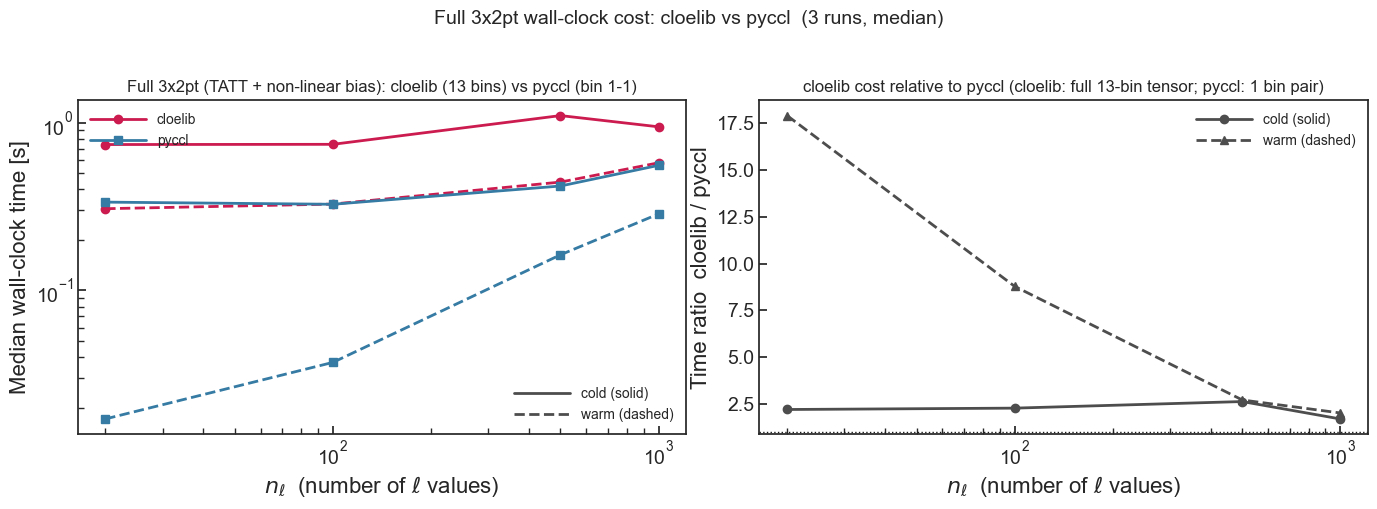

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax_t, ax_r = axes
nell_arr = np.array(nell_values_ia)

pal = {"cloelib": sns.color_palette("rocket", 3)[1], "pyccl": sns.color_palette("mako", 3)[1]}
for label, data, marker in [("cloelib", results_full, 'o'), ("pyccl", results_pyccl_full, 's')]:
    cold = np.array([data["cold"][n] for n in nell_values_ia])
    warm = np.array([data["warm"][n] for n in nell_values_ia])
    ax_t.plot(nell_arr, cold, color=pal[label], lw=2, marker=marker)
    ax_t.plot(nell_arr, warm, color=pal[label], lw=2, marker=marker, ls='--')

ax_t.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_t.set_ylabel('Median wall-clock time [s]')
ax_t.set_title('Full 3x2pt (TATT + non-linear bias): cloelib (13 bins) vs pyccl (bin 1-1)')
ax_t.set_xscale('log'); ax_t.set_yscale('log')
cold_warm_legends(ax_t, [('cloelib', pal['cloelib'], 'o'), ('pyccl', pal['pyccl'], 's')], fontsize=10)
ax_t.tick_params(axis='both', which='both', direction='in')

ratio_cold = np.array([results_full["cold"][n] / results_pyccl_full["cold"][n] for n in nell_values_ia])
ratio_warm = np.array([results_full["warm"][n] / results_pyccl_full["warm"][n] for n in nell_values_ia])
ax_r.plot(nell_arr, ratio_cold, color='0.3', lw=2, marker='o', label='cold (solid)')
ax_r.plot(nell_arr, ratio_warm, color='0.3', lw=2, marker='^', ls='--', label='warm (dashed)')
ax_r.axhline(1.0, color='k', lw=1, ls=':')
ax_r.set_xlabel(r'$n_\ell$  (number of $\ell$ values)')
ax_r.set_ylabel('Time ratio  cloelib / pyccl')
ax_r.set_title('cloelib cost relative to pyccl (cloelib: full 13-bin tensor; pyccl: 1 bin pair)')
ax_r.set_xscale('log')
ax_r.legend(fontsize=10, frameon=False)
ax_r.tick_params(axis='both', which='both', direction='in')

plt.suptitle('Full 3x2pt wall-clock cost: cloelib vs pyccl  (%d runs, median)' % N_REPEAT_IA, fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('time_comparison_cloelib_vs_pyccl_full3x2pt.png', dpi=150, bbox_inches='tight')
plt.show()

Combining TATT and non-linear galaxy bias amplifies the batching story even further: **cloelib computes the full 13-bin, 3-probe tensor (GC-GC's 91 bin pairs + GC-WL's 169 + WL-WL's 91) in about the same wall-clock time pyccl needs for a *single* bin pair** at small $n_\ell$ - warm ratio ~18x at $n_\ell=20$, dropping to ~2x by $n_\ell=1000$ as pyccl's own per-$\ell$ integration cost (not batched over bin pairs either way) starts to dominate over its lack of cross-bin batching. Cold timings (which include a fresh FAST-PT rebuild - both the TATT and the non-linear-bias kernels - on both sides) stay close throughout, ~1.7-2.6x, since that one-time cost dominates at every $n_\ell$ sampled here and is comparable between the two codes (same underlying `fast-pt` package, as established in the TATT section above).

As in the TATT-only comparison, this is `cloelib`'s existing batching advantage (the whole tensor is one compiled XLA call) applying just as cleanly once *both* the intrinsic-alignment and galaxy-bias models are upgraded together - neither addition touches that batching; they just add more (cheaply summed) terms inside the same vectorized `Cl_integration` call. The same caveat as the TATT section applies: this is a timing comparison, not a precision cross-validation one - `cloelib` (HMCode2020Emu) and `pyccl` (halofit) use different nonlinear matter power spectrum prescriptions, so absolute $C_\ell$ values aren't expected to agree regardless of the bias/IA modelling.

## All 13-bin combinations at $n_\ell = 32$: cloelib vs pyccl

The sections above compare the two codes either with the linear-bias/NLA setup, or, for TATT + non-linear galaxy bias, with pyccl limited to a single bin pair.
Here both codes compute the **complete 13-bin 3x2pt** at the Euclid-like **$n_\ell = 32$** (log-spaced in $2\le\ell\le2999$, exactly 32 values).
That is $91$ GG ($i\le j$) + $169$ GE (all $i,j$) + $91$ EE ($i\le j$) = **351 spectra**, for both setups:

| setup | cloelib | pyccl `angular_cl` calls |
|---|---|---|
| **NLA + linear bias** ($b=1$) | `PositionsTracer(galaxy_bias_model='poly')` + `ShearTracer(ia_model='NLA')` | 351 (one per spectrum; NLA is folded into the lensing kernel) |
| **TATT + non-linear bias** | `PositionsTracer(galaxy_bias_model='nonlinear')` + `ShearTracer(ia_model='TATT')` | 793: GG 91, GE $2\times169$ ($N\!G$ + $N\!I$), EE $4\times91$ ($GG$ + $GI$ + $IG$ + $II$) |

- **cold**: tracers rebuilt on every repeat. For TATT + non-linear bias this includes fresh `PBJTATTLoopComputer`/`PBJNonlinearBiasLoopComputer` (cloelib) and a fresh `EulerianPTCalculator` + its five `Pk2D`s (pyccl), so both pay their FAST-PT cost.
- **warm**: tracers, loop computers and `Pk2D`s reused, so only the $C_\ell$ computation itself is timed.
- Both: the cosmology (`nonlin_pert` / `cosmo_ccl`) is built once and reused, and one untimed call precedes each timing. For cloelib, that call excludes the one-off JAX compilation for this $\ell$-grid.

In [9]:
ells_32 = np.geomspace(2, 2999, 32)   # exactly 32 log-spaced multipoles
N_REPEAT_32 = 5
bin_keys = list(dndz_norm)
pairs_auto = [(i, j) for i in range(n_bins) for j in range(i, n_bins)]   # GG and EE
pairs_cross = [(i, j) for i in range(n_bins) for j in range(n_bins)]     # GE
print(f"{len(ells_32)} ells | {len(pairs_auto)} GG + {len(pairs_cross)} GE + {len(pairs_auto)} EE "
      f"= {2 * len(pairs_auto) + len(pairs_cross)} spectra")


def median_time(fn, repeat=N_REPEAT_32):
    fn()  # untimed warm-up (JAX compilation, first-call overheads)
    return float(np.median(timeit.repeat(fn, repeat=repeat, number=1)))


# ── NLA + linear bias ────────────────────────────────────────────────────────
def build_cloelib_nla():
    tr_pos = PositionsTracer(perturbations=nonlin_pert, dndz=my_dndz_norm, z=zs,
                             galaxy_bias_model='poly', nuisance_params=nuisance_pos)
    tr_she = ShearTracer(perturbations=nonlin_pert, dndz=my_dndz_norm, z=zs,
                         nuisance_params=nuisance_she, ia_model='NLA')
    return tr_pos, tr_she


ia_bias_nla_z = AIA * CIA * (1.0 + z_nz) ** EtaIA


def build_ccl_nla():
    N = [ccl.NumberCountsTracer(cosmo_ccl, dndz=(z_nz, dndz_norm[k]),
                                bias=(z_nz, np.ones_like(z_nz)), has_rsd=False) for k in bin_keys]
    G = [ccl.WeakLensingTracer(cosmo_ccl, dndz=(z_nz, dndz_norm[k]),
                               ia_bias=(z_nz, ia_bias_nla_z)) for k in bin_keys]
    return N, G


def ccl_nla_3x2pt(N, G):
    cls = {}
    for i, j in pairs_auto:
        cls['GG', i, j] = ccl.angular_cl(cosmo_ccl, N[i], N[j], ells_32)
    for i, j in pairs_cross:
        cls['GE', i, j] = ccl.angular_cl(cosmo_ccl, N[i], G[j], ells_32)
    for i, j in pairs_auto:
        cls['EE', i, j] = ccl.angular_cl(cosmo_ccl, G[i], G[j], ells_32)
    return cls


# ── TATT + non-linear galaxy bias ────────────────────────────────────────────
def build_cloelib_tatt_nl():
    tr_pos = build_pos_tracer_nlbias(PBJNonlinearBiasLoopComputer(nonlin_pert))
    tr_she = build_she_tracer("TATT", PBJTATTLoopComputer(nonlin_pert))
    return tr_pos, tr_she


def build_ccl_tatt_nl():
    # PT calculator + the five biased P(k,z) from the bin-1 builder above (bin-independent),
    # then one (N, G, I) tracer triplet per bin
    _, _, _, pk_gg, pk_gG, pk_gI, pk_GI, pk_II = build_ccl_full_3x2pt(C1_z, C2_z, C1delta_z)
    N = [ccl.NumberCountsTracer(cosmo_ccl, dndz=(z_nz, dndz_norm[k]),
                                bias=(z_nz, np.ones_like(z_nz)), has_rsd=False) for k in bin_keys]
    G = [ccl.WeakLensingTracer(cosmo_ccl, dndz=(z_nz, dndz_norm[k]), has_shear=True, ia_bias=None)
         for k in bin_keys]
    I = [ccl.WeakLensingTracer(cosmo_ccl, dndz=(z_nz, dndz_norm[k]), has_shear=False,
                               ia_bias=(z_nz, np.ones_like(z_nz)), use_A_ia=False) for k in bin_keys]
    return N, G, I, (pk_gg, pk_gG, pk_gI, pk_GI, pk_II)


def ccl_tatt_nl_3x2pt(N, G, I, pks):
    pk_gg, pk_gG, pk_gI, pk_GI, pk_II = pks
    cls = {}
    for i, j in pairs_auto:
        cls['GG', i, j] = ccl.angular_cl(cosmo_ccl, N[i], N[j], ells_32, p_of_k_a=pk_gg)
    for i, j in pairs_cross:
        cls['GE', i, j] = (ccl.angular_cl(cosmo_ccl, N[i], G[j], ells_32, p_of_k_a=pk_gG)
                           + ccl.angular_cl(cosmo_ccl, N[i], I[j], ells_32, p_of_k_a=pk_gI))
    for i, j in pairs_auto:
        cls['EE', i, j] = (ccl.angular_cl(cosmo_ccl, G[i], G[j], ells_32)
                           + ccl.angular_cl(cosmo_ccl, G[i], I[j], ells_32, p_of_k_a=pk_GI)
                           + ccl.angular_cl(cosmo_ccl, I[i], G[j], ells_32, p_of_k_a=pk_GI)
                           + ccl.angular_cl(cosmo_ccl, I[i], I[j], ells_32, p_of_k_a=pk_II))
    return cls


# Sanity: both codes return all 351 spectra, finite
_cl = compute_full_3x2pt_cloelib(*build_cloelib_tatt_nl(), ells_32)
_cc = ccl_tatt_nl_3x2pt(*build_ccl_tatt_nl())
print(f"cloelib: {len(_cl)} spectrum keys | pyccl: {len(_cc)} spectra, all finite: "
      f"{all(np.all(np.isfinite(v)) for v in _cc.values())}")

32 ells | 91 GG + 169 GE + 91 EE = 351 spectra


cloelib: 351 spectrum keys | pyccl: 351 spectra, all finite: True


In [10]:
setups = {
    'NLA + linear bias': dict(
        cloelib_build=build_cloelib_nla,
        ccl_build=build_ccl_nla, ccl_cls=ccl_nla_3x2pt, ccl_calls=351),
    'TATT + non-linear bias': dict(
        cloelib_build=build_cloelib_tatt_nl,
        ccl_build=build_ccl_tatt_nl, ccl_cls=ccl_tatt_nl_3x2pt, ccl_calls=793),
}
results_32 = {}

for name, s in setups.items():
    r = {}
    # cloelib
    r['cloelib', 'cold'] = median_time(lambda: compute_full_3x2pt_cloelib(*s['cloelib_build'](), ells_32))
    tr_w = s['cloelib_build']()
    r['cloelib', 'warm'] = median_time(lambda: compute_full_3x2pt_cloelib(*tr_w, ells_32))
    # pyccl
    r['pyccl', 'cold'] = median_time(lambda: s['ccl_cls'](*s['ccl_build']()))
    objs_w = s['ccl_build']()
    r['pyccl', 'warm'] = median_time(lambda: s['ccl_cls'](*objs_w))
    results_32[name] = r

print(f"13 bins, 351 spectra, n_ell = {len(ells_32)}  (median of {N_REPEAT_32} runs)\n")
print(f"{'setup':24s} {'':5s} {'cloelib':>9s} {'pyccl':>9s} {'pyccl/cloelib':>14s}")
for name, r in results_32.items():
    for mode in ('cold', 'warm'):
        c, p = r['cloelib', mode], r['pyccl', mode]
        print(f"{name:24s} {mode:5s} {c:8.3f}s {p:8.3f}s {p / c:13.1f}x")
    print(f"{'':24s} pyccl: {setups[name]['ccl_calls']} angular_cl calls per evaluation")

13 bins, 351 spectra, n_ell = 32  (median of 5 runs)

setup                            cloelib     pyccl  pyccl/cloelib
NLA + linear bias        cold     0.128s    0.790s           6.2x
NLA + linear bias        warm     0.129s    0.738s           5.7x
                         pyccl: 351 angular_cl calls per evaluation
TATT + non-linear bias   cold     0.405s    1.858s           4.6x
TATT + non-linear bias   warm     0.194s    1.593s           8.2x
                         pyccl: 793 angular_cl calls per evaluation


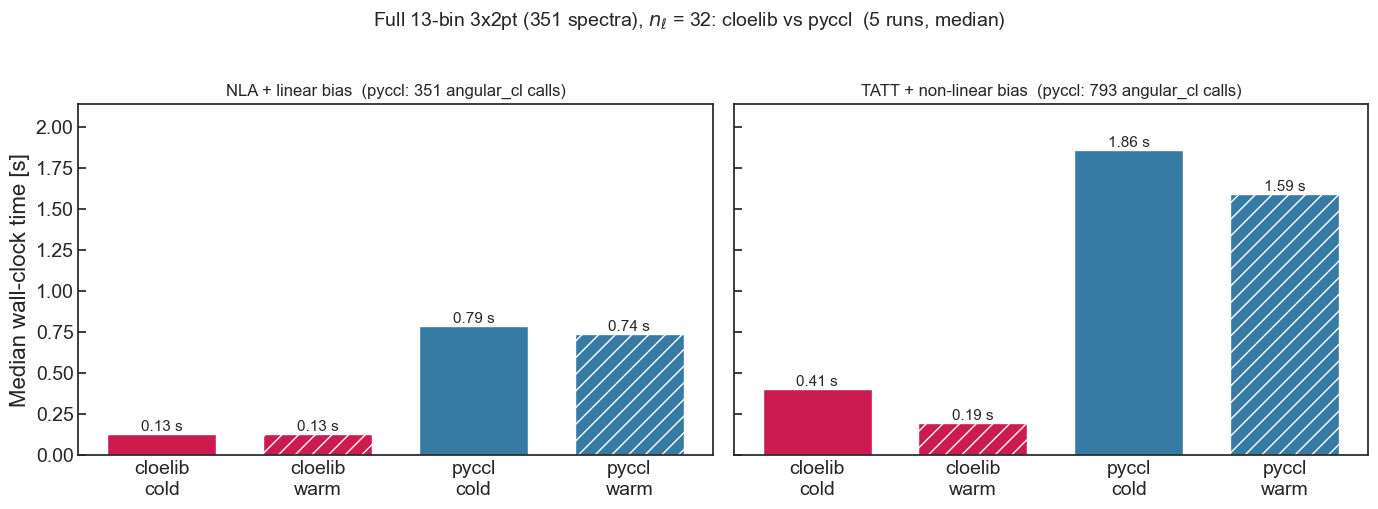

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
col = {'cloelib': sns.color_palette("rocket", 3)[1], 'pyccl': sns.color_palette("mako", 3)[1]}
bars = [('cloelib', 'cold'), ('cloelib', 'warm'), ('pyccl', 'cold'), ('pyccl', 'warm')]

for ax, (name, r) in zip(axes, results_32.items()):
    x = np.arange(len(bars))
    vals = [r[b] for b in bars]
    ax.bar(x, vals, color=[col[code] for code, _ in bars],
           hatch=['' if mode == 'cold' else '//' for _, mode in bars], edgecolor='white', width=0.7)
    for xi, v in zip(x, vals):
        ax.text(xi, v, f'{v:.2f} s', ha='center', va='bottom', fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{code}\n{mode}' for code, mode in bars])
    ax.set_title(f'{name}  (pyccl: {setups[name]["ccl_calls"]} angular_cl calls)', fontsize=12)
    ax.tick_params(axis='both', which='both', direction='in')
axes[0].set_ylabel('Median wall-clock time [s]')
axes[0].set_ylim(0, max(max(r.values()) for r in results_32.values()) * 1.15)

plt.suptitle(f'Full 13-bin 3x2pt (351 spectra), $n_\\ell$ = {len(ells_32)}: cloelib vs pyccl  '
             f'({N_REPEAT_32} runs, median)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('time_comparison_cloelib_vs_pyccl_13bins_nell32.png', dpi=150, bbox_inches='tight')
plt.show()

**With every bin combination computed on both sides, cloelib is faster in all four cases**: ~6x for NLA + linear bias (0.13 s vs ~0.75 s, cold or warm), and ~4.6x cold / ~8x warm for TATT + non-linear bias (0.41 s / 0.19 s vs 1.86 s / 1.59 s).
Timings vary by ~10% between runs.

- **pyccl scales with its number of `angular_cl` calls.** Going from NLA + linear bias to TATT + non-linear bias multiplies the calls by 793/351 = 2.3, and its warm time by ~2.2. Each extra term is a separate call over all bin pairs.
- **cloelib barely notices the extra terms once warm** (0.13 s → 0.19 s, ~1.5x): the extra `PkTerm`s are summed inside the same batched Limber call over the whole 13-bin tensor.
- **Cold costs** add the FAST-PT setup (~0.2 s) on both sides, which is why the TATT + non-linear bias cold ratio (~4.6x) is lower than the warm one.

This reverses the single-bin-pair picture in the sections above, where pyccl was faster warm at small $n_\ell$: a realistic 13-bin 3x2pt at $n_\ell=32$ is dominated by pyccl's per-pair calls, which cloelib batches away.